In [1]:
# استيراد مكتبة pandas للتعامل مع البيانات وتحليلها
import pandas as pd

# استيراد مكتبة numpy للعمليات الحسابية
import numpy as np

# استيراد مكتبة os للتعامل مع الملفات والمسارات
import os

# تحديد اسم ملف البيانات الذي دمجناه سابقاً
file_path = "BTS_2019_2026_MERGED.csv"

# قراءة ملف CSV مع low_memory=False لتقليل مشاكل استنتاج أنواع الأعمدة
df = pd.read_csv(file_path, low_memory=False)

# عرض رسالة تؤكد نجاح قراءة البيانات
print("تم تحميل البيانات بنجاح")

# عرض عدد الصفوف والأعمدة لمعرفة حجم مجموعة البيانات
print("حجم البيانات:", df.shape)

# عرض أول خمسة سجلات للتأكد من شكل البيانات
display(df.head())

تم تحميل البيانات بنجاح
حجم البيانات: (3459548, 24)


,DEPARTURES_SCHEDULED,DEPARTURES_PERFORMED,SEATS,PASSENGERS,DISTANCE,AIR_TIME,UNIQUE_CARRIER,AIRLINE_ID,UNIQUE_CARRIER_NAME,ORIGIN_AIRPORT_ID,...,DEST,DEST_CITY_NAME,DEST_STATE_ABR,AIRCRAFT_GROUP,AIRCRAFT_TYPE,YEAR,QUARTER,MONTH,CLASS,DATA_SOURCE
0,0.0,0.0,0.0,0.0,0.0,0.0,M6,20151.0,Amerijet International,14100,...,PHL,"Philadelphia, PA",PA,6,626,2023,3,8,G,DU
1,0.0,0.0,0.0,0.0,16.0,0.0,DL,19790.0,Delta Air Lines Inc.,10540,...,BOS,"Boston, MA",MA,6,622,2023,4,10,L,DU
2,0.0,0.0,0.0,0.0,17.0,0.0,DL,19790.0,Delta Air Lines Inc.,12954,...,LAX,"Los Angeles, CA",CA,6,622,2023,4,10,L,DU
3,0.0,0.0,0.0,0.0,17.0,0.0,NEW,20273.0,New England Airlines Inc.,10613,...,WST,"Westerly, RI",RI,0,79,2023,1,1,F,DU
4,0.0,0.0,0.0,0.0,17.0,0.0,NEW,20273.0,New England Airlines Inc.,10613,...,WST,"Westerly, RI",RI,0,79,2023,2,5,F,DU


In [2]:
# عرض أسماء جميع الأعمدة وأنواع البيانات الخاصة بها
# نحتاج معرفة نوع كل عمود لتحديد كيفية التعامل معه لاحقاً
print("معلومات الأعمدة وأنواع البيانات:")
df.info()

# حساب عدد القيم المفقودة في كل عمود
# يساعدنا ذلك على معرفة الأعمدة التي تحتوي على بيانات ناقصة
print("\nعدد القيم المفقودة في كل عمود:")
print(df.isnull().sum())

# حساب عدد الصفوف المكررة بالكامل
# نحتاج معرفة ما إذا كانت هناك سجلات متطابقة في مجموعة البيانات
print("\nعدد الصفوف المكررة:")
print(df.duplicated().sum())

# عرض إحصائيات وصفية للأعمدة الرقمية
# تساعدنا على فهم نطاق القيم وتوزيع البيانات
print("\nالإحصائيات الوصفية للأعمدة الرقمية:")
display(df.describe())

معلومات الأعمدة وأنواع البيانات:
<class 'pandas.DataFrame'>
RangeIndex: 3459548 entries, 0 to 3459547
Data columns (total 24 columns):
 #   Column                Dtype  
---  ------                -----  
 0   DEPARTURES_SCHEDULED  float64
 1   DEPARTURES_PERFORMED  float64
 2   SEATS                 float64
 3   PASSENGERS            float64
 4   DISTANCE              float64
 5   AIR_TIME              float64
 6   UNIQUE_CARRIER        str    
 7   AIRLINE_ID            float64
 8   UNIQUE_CARRIER_NAME   str    
 9   ORIGIN_AIRPORT_ID     int64  
 10  ORIGIN                str    
 11  ORIGIN_CITY_NAME      str    
 12  ORIGIN_STATE_ABR      str    
 13  DEST_AIRPORT_ID       int64  
 14  DEST                  str    
 15  DEST_CITY_NAME        str    
 16  DEST_STATE_ABR        str    
 17  AIRCRAFT_GROUP        int64  
 18  AIRCRAFT_TYPE         int64  
 19  YEAR                  int64  
 20  QUARTER               int64  
 21  MONTH                 int64  
 22  CLASS               

,DEPARTURES_SCHEDULED,DEPARTURES_PERFORMED,SEATS,PASSENGERS,DISTANCE,AIR_TIME,AIRLINE_ID,ORIGIN_AIRPORT_ID,DEST_AIRPORT_ID,AIRCRAFT_GROUP,AIRCRAFT_TYPE,YEAR,QUARTER,MONTH
count,3.459548e+06,3.459548e+06,3.459548e+06,3.459548e+06,3.459548e+06,3.459548e+06,3.459524e+06,3.459548e+06,3.459548e+06,3.459548e+06,3.459548e+06,3.459548e+06,3.459548e+06,3.459548e+06
mean,1.946802e+01,1.999669e+01,2.345643e+03,1.833463e+03,9.035801e+02,2.383094e+03,2.020997e+04,1.279085e+04,1.278216e+04,5.563260e+00,6.294975e+02,2.022527e+03,2.448903e+00,6.344703e+00
std,3.319117e+01,3.201093e+01,4.378565e+03,3.578086e+03,9.306865e+02,4.282430e+03,5.774881e+02,1.597321e+03,1.596367e+03,1.404335e+00,1.672478e+02,2.199630e+00,1.114512e+00,3.439051e+00
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.939300e+04,1.000100e+04,1.000100e+04,0.000000e+00,1.000000e+01,2.019000e+03,1.000000e+00,1.000000e+00
25%,1.000000e+00,1.000000e+00,7.000000e+01,1.100000e+01,3.050000e+02,1.500000e+02,1.980500e+04,1.129200e+04,1.129200e+04,6.000000e+00,6.140000e+02,2.021000e+03,1.000000e+00,3.000000e+00
50%,6.000000e+00,8.000000e+00,5.250000e+02,3.470000e+02,6.780000e+02,7.440000e+02,2.022400e+04,1.289200e+04,1.288900e+04,6.000000e+00,6.460000e+02,2.023000e+03,2.000000e+00,6.000000e+00
75%,2.700000e+01,2.700000e+01,3.003000e+03,2.254000e+03,1.143000e+03,2.887000e+03,2.040900e+04,1.410700e+04,1.410000e+04,6.000000e+00,6.980000e+02,2.024000e+03,3.000000e+00,9.000000e+00
max,2.170000e+03,1.574000e+03,1.080320e+05,8.662300e+04,9.886000e+03,7.610160e+05,2.213700e+04,1.724500e+04,1.724400e+04,8.000000e+00,8.940000e+02,2.026000e+03,4.000000e+00,1.200000e+01


In [3]:
# حساب عدد السجلات الموجودة في كل سنة
# يساعدنا على معرفة توزيع البيانات الزمنية
year_counts = df['YEAR'].value_counts().sort_index()

# طباعة عدد السجلات لكل سنة
print("عدد السجلات حسب السنة:")
print(year_counts)

# حساب مجموع الرحلات المنفذة في كل سنة
# نستخدم DEPARTURES_PERFORMED لأنه المتغير المستهدف في المشروع
yearly_flights = df.groupby('YEAR')['DEPARTURES_PERFORMED'].sum()

# عرض إجمالي الرحلات المنفذة لكل سنة
print("\nإجمالي الرحلات المنفذة حسب السنة:")
print(yearly_flights)

# حساب مجموع الرحلات المنفذة حسب الشهر
# يساعدنا على استكشاف اختلاف الطلب بين أشهر السنة
monthly_flights = df.groupby('MONTH')['DEPARTURES_PERFORMED'].sum()

# عرض إجمالي الرحلات المنفذة لكل شهر
print("\nإجمالي الرحلات المنفذة حسب الشهر:")
print(monthly_flights)

عدد السجلات حسب السنة:
YEAR
2019    442909
2020    328955
2021    427142
2022    462886
2023    480378
2024    496740
2025    517764
2026    302774
Name: count, dtype: int64

إجمالي الرحلات المنفذة حسب السنة:
YEAR
2019    10252985.0
2020     6371881.0
2021     8212492.0
2022     9068244.0
2023     9503873.0
2024     9865162.0
2025    10049810.0
2026     5855059.0
Name: DEPARTURES_PERFORMED, dtype: float64

إجمالي الرحلات المنفذة حسب الشهر:
MONTH
1     5874210.0
2     5508619.0
3     6336805.0
4     5784740.0
5     6072473.0
6     6181918.0
7     6560249.0
8     5637936.0
9     5178551.0
10    5440035.0
11    5212057.0
12    5391913.0
Name: DEPARTURES_PERFORMED, dtype: float64


In [4]:
# تجميع البيانات حسب السنة والشهر
# كل مجموعة تمثل شهرًا واحدًا من سنة محددة
monthly_data = df.groupby(['YEAR', 'MONTH']).agg(
    # جمع عدد الرحلات المنفذة خلال الشهر ليكون هو قيمة الهدف
    TOTAL_DEPARTURES=('DEPARTURES_PERFORMED', 'sum'),

    # حساب عدد السجلات التي ساهمت في تكوين إجمالي الشهر
    RECORD_COUNT=('DEPARTURES_PERFORMED', 'count')
).reset_index()

# حساب عدد الأشهر المتوفرة في كل سنة
# نستخدم عدد الأشهر المختلفة لمعرفة اكتمال البيانات الزمنية
months_per_year = monthly_data.groupby('YEAR')['MONTH'].nunique()

# عرض عدد الأشهر المتوفرة لكل سنة
print("عدد الأشهر المتوفرة في كل سنة:")
print(months_per_year)

# عرض بيانات سنة 2026 لمعرفة الأشهر الموجودة فيها
print("\nبيانات سنة 2026:")
display(monthly_data[monthly_data['YEAR'] == 2026])

# عرض أول عشرة سجلات من البيانات الشهرية المجمعة
# للتأكد من أن عملية التجميع تمت بالشكل الصحيح
print("\nعينة من البيانات الشهرية:")
display(monthly_data.head(10))

عدد الأشهر المتوفرة في كل سنة:
YEAR
2019    12
2020    12
2021    12
2022    12
2023    12
2024    12
2025    12
2026     7
Name: MONTH, dtype: int64

بيانات سنة 2026:


,YEAR,MONTH,TOTAL_DEPARTURES,RECORD_COUNT
84,2026,1,760752.0,43617
85,2026,2,730468.0,40903
86,2026,3,860680.0,44511
87,2026,4,849710.0,42596
88,2026,5,872235.0,43707
89,2026,6,876674.0,43390
90,2026,7,904540.0,44050



عينة من البيانات الشهرية:


,YEAR,MONTH,TOTAL_DEPARTURES,RECORD_COUNT
0,2019,1,803572.0,36719
1,2019,2,730386.0,35040
2,2019,3,870753.0,36608
3,2019,4,844735.0,35611
4,2019,5,881526.0,35817
5,2019,6,884499.0,38482
6,2019,7,919069.0,37145
7,2019,8,918013.0,38230
8,2019,9,832500.0,35286
9,2019,10,875999.0,35849


In [5]:
# إنشاء نسخة من البيانات الشهرية للعمل عليها دون تغيير البيانات الأصلية
model_data = monthly_data.copy()

# إنشاء عمود DATE بدمج السنة والشهر وتحويلهما إلى تاريخ
# هذا يساعدنا على ترتيب السجلات زمنيًا
model_data['DATE'] = pd.to_datetime(
    model_data['YEAR'].astype(str) + '-' +
    model_data['MONTH'].astype(str) + '-01'
)

# ترتيب البيانات من أقدم شهر إلى أحدث شهر
# الترتيب الزمني ضروري قبل تقسيم البيانات وتدريب نماذج التنبؤ
model_data = model_data.sort_values('DATE').reset_index(drop=True)

# التأكد من عدد السجلات الشهرية
print("عدد السجلات الشهرية:", len(model_data))

# التأكد من عدم وجود أشهر مكررة
print("عدد التواريخ المكررة:", model_data['DATE'].duplicated().sum())

# عرض بداية ونهاية الفترة الزمنية
print("أول شهر:", model_data['DATE'].min())
print("آخر شهر:", model_data['DATE'].max())

# عرض البيانات بعد ترتيبها زمنيًا
display(model_data.head(10))
display(model_data.tail(10))

عدد السجلات الشهرية: 91
عدد التواريخ المكررة: 0
أول شهر: 2019-01-01 00:00:00
آخر شهر: 2026-07-01 00:00:00


,YEAR,MONTH,TOTAL_DEPARTURES,RECORD_COUNT,DATE
0,2019,1,803572.0,36719,2019-01-01
1,2019,2,730386.0,35040,2019-02-01
2,2019,3,870753.0,36608,2019-03-01
3,2019,4,844735.0,35611,2019-04-01
4,2019,5,881526.0,35817,2019-05-01
5,2019,6,884499.0,38482,2019-06-01
6,2019,7,919069.0,37145,2019-07-01
7,2019,8,918013.0,38230,2019-08-01
8,2019,9,832500.0,35286,2019-09-01
9,2019,10,875999.0,35849,2019-10-01


,YEAR,MONTH,TOTAL_DEPARTURES,RECORD_COUNT,DATE
81,2025,10,864979.0,43348,2025-10-01
82,2025,11,801810.0,44014,2025-11-01
83,2025,12,839426.0,44832,2025-12-01
84,2026,1,760752.0,43617,2026-01-01
85,2026,2,730468.0,40903,2026-02-01
86,2026,3,860680.0,44511,2026-03-01
87,2026,4,849710.0,42596,2026-04-01
88,2026,5,872235.0,43707,2026-05-01
89,2026,6,876674.0,43390,2026-06-01
90,2026,7,904540.0,44050,2026-07-01


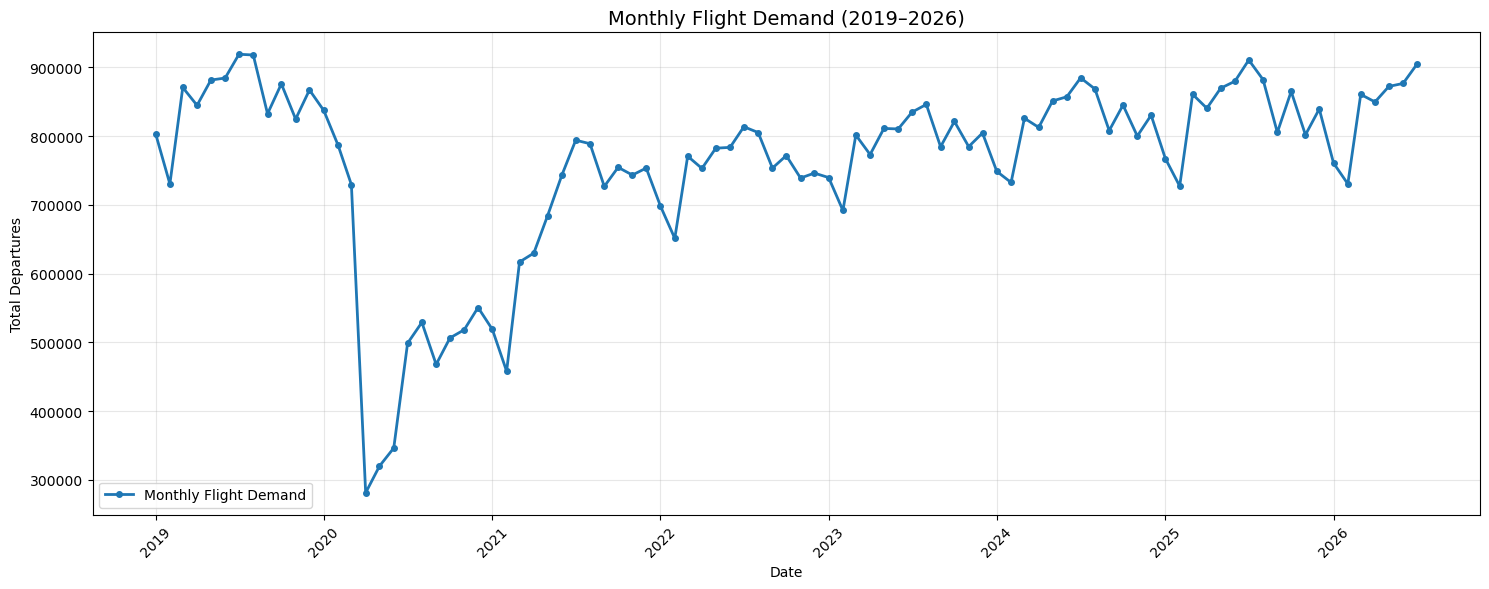

In [6]:
# استيراد مكتبة matplotlib لإنشاء الرسوم البيانية
import matplotlib.pyplot as plt

# تحديد حجم الرسم البياني ليكون واضحاً
plt.figure(figsize=(15, 6))

# رسم إجمالي الرحلات المنفذة لكل شهر
# المحور الأفقي يمثل التاريخ والمحور الرأسي يمثل عدد الرحلات
plt.plot(
    model_data['DATE'],
    model_data['TOTAL_DEPARTURES'],
    marker='o',
    linewidth=2,
    markersize=4,
    label='Monthly Flight Demand'
)

# إضافة عنوان يوضح محتوى الرسم
plt.title('Monthly Flight Demand (2019–2026)', fontsize=14)

# تسمية المحور الأفقي
plt.xlabel('Date')

# تسمية المحور الرأسي
plt.ylabel('Total Departures')

# إضافة شبكة لتسهيل قراءة القيم
plt.grid(True, alpha=0.3)

# إظهار وسيلة الإيضاح
plt.legend()

# ضبط شكل التاريخ على المحور الأفقي
plt.xticks(rotation=45)

# عرض الرسم البياني
plt.tight_layout()
plt.show()

In [7]:
# حساب الإحصائيات الوصفية لمتغير الطلب على الرحلات
# تساعدنا على معرفة متوسط الطلب وأقل وأعلى قيمة والانحراف المعياري
display(model_data['TOTAL_DEPARTURES'].describe())

# تحديد الشهر الذي سجل أعلى عدد من الرحلات
highest_month = model_data.loc[
    model_data['TOTAL_DEPARTURES'].idxmax()
]

# تحديد الشهر الذي سجل أقل عدد من الرحلات
lowest_month = model_data.loc[
    model_data['TOTAL_DEPARTURES'].idxmin()
]

# عرض الشهر صاحب أعلى طلب
print("أعلى طلب على الرحلات:")
display(highest_month)

# عرض الشهر صاحب أقل طلب
print("أقل طلب على الرحلات:")
display(lowest_month)

count        91.000000
mean     760214.351648
std      133410.912027
min      281116.000000
25%      735790.500000
50%      800074.000000
75%      845606.000000
max      919069.000000
Name: TOTAL_DEPARTURES, dtype: float64

أعلى طلب على الرحلات:


YEAR                               2019
MONTH                                 7
TOTAL_DEPARTURES               919069.0
RECORD_COUNT                      37145
DATE                2019-07-01 00:00:00
Name: 6, dtype: object

أقل طلب على الرحلات:


YEAR                               2020
MONTH                                 4
TOTAL_DEPARTURES               281116.0
RECORD_COUNT                      21256
DATE                2020-04-01 00:00:00
Name: 15, dtype: object

In [8]:
# تحديد عدد الأشهر التي سنستخدمها للاختبار
# نحتفظ بآخر 18 شهرًا لقياس قدرة النماذج على التنبؤ بالمستقبل
test_size = 18

# تحديد نقطة الفصل بين بيانات التدريب والاختبار
# يتم الفصل حسب ترتيب التاريخ وليس بطريقة عشوائية
split_index = len(model_data) - test_size

# إنشاء بيانات التدريب من الأشهر السابقة لنقطة الفصل
train_data = model_data.iloc[:split_index].copy()

# إنشاء بيانات الاختبار من آخر 18 شهرًا
test_data = model_data.iloc[split_index:].copy()

# عرض عدد الأشهر في كل مجموعة
print("عدد أشهر التدريب:", len(train_data))
print("عدد أشهر الاختبار:", len(test_data))

# عرض الفترة الزمنية لبيانات التدريب
print("\nفترة التدريب:")
print(train_data['DATE'].min(), "إلى", train_data['DATE'].max())

# عرض الفترة الزمنية لبيانات الاختبار
print("\nفترة الاختبار:")
print(test_data['DATE'].min(), "إلى", test_data['DATE'].max())

عدد أشهر التدريب: 73
عدد أشهر الاختبار: 18

فترة التدريب:
2019-01-01 00:00:00 إلى 2025-01-01 00:00:00

فترة الاختبار:
2025-02-01 00:00:00 إلى 2026-07-01 00:00:00


In [9]:
# حساب الحد الأول والثاني باستخدام بيانات التدريب فقط
# نستخدم الثلث الأول والثلث الثاني لتقسيم الطلب إلى ثلاث فئات
low_threshold = train_data['TOTAL_DEPARTURES'].quantile(1/3)
high_threshold = train_data['TOTAL_DEPARTURES'].quantile(2/3)

# عرض حدود التصنيف التي تم حسابها
print("حد الطلب المنخفض إلى المتوسط:", low_threshold)
print("حد الطلب المتوسط إلى المرتفع:", high_threshold)

# إنشاء دالة لتصنيف عدد الرحلات إلى ثلاث مستويات
# نستخدم نفس الحدود لجميع البيانات لضمان عدالة المقارنة
def classify_demand(value):
    if value <= low_threshold:
        return 'Low'
    elif value <= high_threshold:
        return 'Medium'
    else:
        return 'High'

# تطبيق التصنيف على بيانات التدريب
train_data['DEMAND_LEVEL'] = train_data['TOTAL_DEPARTURES'].apply(classify_demand)

# تطبيق الحدود نفسها على بيانات الاختبار
test_data['DEMAND_LEVEL'] = test_data['TOTAL_DEPARTURES'].apply(classify_demand)

# عرض توزيع فئات الطلب في بيانات التدريب
print("\nتوزيع مستويات الطلب في بيانات التدريب:")
print(train_data['DEMAND_LEVEL'].value_counts())

# عرض توزيع فئات الطلب في بيانات الاختبار
print("\nتوزيع مستويات الطلب في بيانات الاختبار:")
print(test_data['DEMAND_LEVEL'].value_counts())

# عرض عينة من البيانات بعد إضافة فئة الطلب
display(train_data[['DATE', 'TOTAL_DEPARTURES', 'DEMAND_LEVEL']].head(10))

حد الطلب المنخفض إلى المتوسط: 743399.0
حد الطلب المتوسط إلى المرتفع: 810407.0

توزيع مستويات الطلب في بيانات التدريب:
DEMAND_LEVEL
Low       25
Medium    24
High      24
Name: count, dtype: int64

توزيع مستويات الطلب في بيانات الاختبار:
DEMAND_LEVEL
High      13
Medium     3
Low        2
Name: count, dtype: int64


,DATE,TOTAL_DEPARTURES,DEMAND_LEVEL
0,2019-01-01,803572.0,Medium
1,2019-02-01,730386.0,Low
2,2019-03-01,870753.0,High
3,2019-04-01,844735.0,High
4,2019-05-01,881526.0,High
5,2019-06-01,884499.0,High
6,2019-07-01,919069.0,High
7,2019-08-01,918013.0,High
8,2019-09-01,832500.0,High
9,2019-10-01,875999.0,High


In [10]:
# إنشاء نسخة مستقلة من البيانات الشهرية لإعداد الخصائص
features_data = model_data.copy()

# إنشاء متغير زمني متسلسل يبدأ من الصفر
# يساعد النموذج على تعلم اتجاه تغير الطلب بمرور الوقت
features_data['TIME_INDEX'] = np.arange(len(features_data))

# إضافة عدد الرحلات في الشهر السابق
# نستخدم shift(1) لمنع استخدام قيمة الشهر الحالي في التنبؤ
features_data['LAG_1'] = features_data['TOTAL_DEPARTURES'].shift(1)

# إضافة عدد الرحلات قبل شهرين
features_data['LAG_2'] = features_data['TOTAL_DEPARTURES'].shift(2)

# إضافة عدد الرحلات قبل ثلاثة أشهر
features_data['LAG_3'] = features_data['TOTAL_DEPARTURES'].shift(3)

# إضافة عدد الرحلات في نفس الشهر من السنة السابقة
# يساعد ذلك على تعلم الأنماط الموسمية السنوية
features_data['LAG_12'] = features_data['TOTAL_DEPARTURES'].shift(12)

# حساب متوسط الرحلات خلال الأشهر الثلاثة السابقة
# نستخدم shift(1) حتى لا يدخل الشهر الحالي في حساب المتوسط
features_data['ROLLING_MEAN_3'] = (
    features_data['TOTAL_DEPARTURES'].shift(1).rolling(window=3).mean()
)

# حساب متوسط الرحلات خلال الأشهر الستة السابقة
features_data['ROLLING_MEAN_6'] = (
    features_data['TOTAL_DEPARTURES'].shift(1).rolling(window=6).mean()
)

# حساب متوسط الرحلات خلال الاثني عشر شهراً السابقة
features_data['ROLLING_MEAN_12'] = (
    features_data['TOTAL_DEPARTURES'].shift(1).rolling(window=12).mean()
)

# إضافة مستوى الطلب الفعلي باستخدام حدود التصنيف المحسوبة من التدريب
features_data['DEMAND_LEVEL'] = features_data['TOTAL_DEPARTURES'].apply(
    classify_demand
)

# حذف الصفوف التي لا تتوفر لها بيانات الأشهر السابقة
# تظهر هذه القيم الناقصة في بداية السلسلة بسبب إنشاء خصائص التأخير
features_data = features_data.dropna().reset_index(drop=True)

# عرض أسماء الخصائص التي ستستخدمها النماذج
feature_columns = [
    'YEAR',
    'MONTH',
    'TIME_INDEX',
    'LAG_1',
    'LAG_2',
    'LAG_3',
    'LAG_12',
    'ROLLING_MEAN_3',
    'ROLLING_MEAN_6',
    'ROLLING_MEAN_12'
]

# عرض عدد السجلات المتبقية بعد تجهيز الخصائص
print("عدد السجلات بعد تجهيز الخصائص:", len(features_data))

# عرض عدد الخصائص المستخدمة في النماذج
print("عدد الخصائص:", len(feature_columns))

# عرض أول خمسة سجلات للتأكد من صحة الخصائص
display(features_data[['DATE', 'TOTAL_DEPARTURES'] + feature_columns[2:]].head())

عدد السجلات بعد تجهيز الخصائص: 79
عدد الخصائص: 10


,DATE,TOTAL_DEPARTURES,TIME_INDEX,LAG_1,LAG_2,LAG_3,LAG_12,ROLLING_MEAN_3,ROLLING_MEAN_6,ROLLING_MEAN_12
0,2020-01-01,837368.0,12,867146.0,824787.0,875999.0,803572.0,855977.333333,872919.000000,854415.416667
1,2020-02-01,786959.0,13,837368.0,867146.0,824787.0,730386.0,843100.333333,859302.166667,857231.750000
2,2020-03-01,729398.0,14,786959.0,837368.0,867146.0,870753.0,830491.000000,837459.833333,861946.166667
3,2020-04-01,281116.0,15,729398.0,786959.0,837368.0,844735.0,784575.000000,820276.166667,850166.583333
4,2020-05-01,319936.0,16,281116.0,729398.0,786959.0,881526.0,599157.666667,721129.000000,803198.333333


In [11]:
# تحديد تاريخ نهاية التدريب المتفق عليه سابقاً
# نستخدم نفس تاريخ الفصل لضمان ثبات منهجية التجربة
split_date = train_data['DATE'].max()

# تحديد بيانات التدريب حسب التاريخ
train_features = features_data[
    features_data['DATE'] <= split_date
].copy()

# تحديد بيانات الاختبار حسب التاريخ
test_features = features_data[
    features_data['DATE'] > split_date
].copy()

# استخراج الخصائص العشر التي ستدخل إلى النماذج
# لا نضيف TOTAL_DEPARTURES أو DEMAND_LEVEL إلى الخصائص
X_train = train_features[feature_columns]
X_test = test_features[feature_columns]

# تحديد المتغير المستهدف العددي وهو إجمالي الرحلات المنفذة شهرياً
y_train = train_features['TOTAL_DEPARTURES']
y_test = test_features['TOTAL_DEPARTURES']

# الاحتفاظ بمستويات الطلب الفعلية لاستخدامها لاحقاً في تقييم التصنيف
y_train_class = train_features['DEMAND_LEVEL']
y_test_class = test_features['DEMAND_LEVEL']

# عرض أحجام بيانات التدريب والاختبار
print("شكل خصائص التدريب:", X_train.shape)
print("شكل خصائص الاختبار:", X_test.shape)

# عرض حجم المتغير المستهدف في التدريب والاختبار
print("\nعدد قيم الهدف في التدريب:", len(y_train))
print("عدد قيم الهدف في الاختبار:", len(y_test))

# التأكد من تاريخ بداية ونهاية كل مجموعة
print("\nفترة التدريب:")
print(train_features['DATE'].min(), "إلى", train_features['DATE'].max())

print("\nفترة الاختبار:")
print(test_features['DATE'].min(), "إلى", test_features['DATE'].max())

# عرض توزيع مستويات الطلب في بيانات الاختبار بعد تجهيز الخصائص
print("\nتوزيع مستويات الطلب في الاختبار:")
print(y_test_class.value_counts())

شكل خصائص التدريب: (61, 10)
شكل خصائص الاختبار: (18, 10)

عدد قيم الهدف في التدريب: 61
عدد قيم الهدف في الاختبار: 18

فترة التدريب:
2020-01-01 00:00:00 إلى 2025-01-01 00:00:00

فترة الاختبار:
2025-02-01 00:00:00 إلى 2026-07-01 00:00:00

توزيع مستويات الطلب في الاختبار:
DEMAND_LEVEL
High      13
Medium     3
Low        2
Name: count, dtype: int64


In [12]:
# استيراد خوارزمية XGBoost الخاصة بالتنبؤ بالقيم الرقمية
from xgboost import XGBRegressor

# إنشاء نموذج XGBoost
# objective='reg:squarederror' لأن هدفنا التنبؤ بعدد الرحلات كقيمة رقمية
# n_estimators يحدد عدد أشجار القرار المستخدمة في النموذج
# max_depth يحدد أقصى عمق للأشجار لتقليل التعقيد
# learning_rate يحدد سرعة تعلم النموذج
# subsample و colsample_bytree يساعدان على تقليل فرط التعلّم
xgb_model = XGBRegressor(
    objective='reg:squarederror',
    n_estimators=100,
    max_depth=2,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

# تدريب نموذج XGBoost باستخدام خصائص التدريب وقيم الرحلات الفعلية
xgb_model.fit(X_train, y_train)

# استخدام النموذج للتنبؤ بعدد الرحلات في بيانات الاختبار
xgb_predictions = xgb_model.predict(X_test)

# منع ظهور أعداد رحلات سالبة لأن عدد الرحلات لا يمكن أن يكون سالباً
xgb_predictions = np.maximum(xgb_predictions, 0)

# عرض رسالة تؤكد اكتمال التدريب
print("تم تدريب نموذج XGBoost بنجاح")

# عرض أول عشر قيم متوقعة من النموذج
print("\nأول عشر تنبؤات لعدد الرحلات:")
print(xgb_predictions[:10])

# مقارنة أول عشر قيم فعلية مع القيم المتوقعة
xgb_comparison = pd.DataFrame({
    'DATE': test_features['DATE'].values,
    'ACTUAL_DEPARTURES': y_test.values,
    'PREDICTED_DEPARTURES': xgb_predictions
})

# عرض جدول المقارنة
display(xgb_comparison.head(10))

تم تدريب نموذج XGBoost بنجاح

أول عشر تنبؤات لعدد الرحلات:
[745429.25 749497.1  831070.44 799509.7  808510.3  811960.   811960.
 834587.8  805045.1  821377.06]


,DATE,ACTUAL_DEPARTURES,PREDICTED_DEPARTURES
0,2025-02-01,727273.0,745429.2500
1,2025-03-01,860838.0,749497.1250
2,2025-04-01,840502.0,831070.4375
3,2025-05-01,869674.0,799509.6875
4,2025-06-01,879848.0,808510.3125
5,2025-07-01,910713.0,811960.0000
6,2025-08-01,882153.0,811960.0000
7,2025-09-01,805351.0,834587.8125
8,2025-10-01,864979.0,805045.1250
9,2025-11-01,801810.0,821377.0625


In [13]:
# استيراد نموذج الشبكة العصبية الاصطناعية
from sklearn.neural_network import MLPRegressor

# استيراد أداة توحيد مقياس البيانات
from sklearn.preprocessing import StandardScaler

# إنشاء أداة لتوحيد خصائص التدريب
scaler_X = StandardScaler()

# حساب المتوسط والانحراف المعياري لخصائص التدريب وتوحيدها
X_train_scaled = scaler_X.fit_transform(X_train)

# توحيد خصائص الاختبار باستخدام نفس مقاييس التدريب
X_test_scaled = scaler_X.transform(X_test)

# إنشاء أداة لتوحيد قيم عدد الرحلات
scaler_y = StandardScaler()

# توحيد قيم الهدف في بيانات التدريب
y_train_scaled = scaler_y.fit_transform(
    y_train.to_numpy().reshape(-1, 1)
).ravel()

# إنشاء نموذج الشبكة العصبية الاصطناعية ANN
ann_model = MLPRegressor(
    hidden_layer_sizes=(16, 8),
    activation='relu',
    solver='adam',
    alpha=0.01,
    learning_rate_init=0.001,
    max_iter=3000,
    random_state=42
)

# تدريب الشبكة العصبية باستخدام بيانات التدريب الموحدة
ann_model.fit(X_train_scaled, y_train_scaled)

# التنبؤ بعدد الرحلات باستخدام بيانات الاختبار الموحدة
ann_predictions_scaled = ann_model.predict(X_test_scaled)

# إعادة التنبؤات إلى مقياس عدد الرحلات الأصلي
ann_predictions = scaler_y.inverse_transform(
    ann_predictions_scaled.reshape(-1, 1)
).ravel()

# منع ظهور أعداد رحلات سالبة
ann_predictions = np.maximum(ann_predictions, 0)

# عرض رسالة تؤكد اكتمال التدريب
print("تم تدريب نموذج ANN بنجاح")

# عرض أول عشر تنبؤات من نموذج ANN
print("\nأول عشر تنبؤات لعدد الرحلات:")
print(ann_predictions[:10])

# إنشاء جدول لمقارنة القيم الفعلية والمتوقعة
ann_comparison = pd.DataFrame({
    'DATE': test_features['DATE'].values,
    'ACTUAL_DEPARTURES': y_test.values,
    'PREDICTED_DEPARTURES': ann_predictions
})

# عرض أول عشر نتائج للمقارنة
display(ann_comparison.head(10))

تم تدريب نموذج ANN بنجاح

أول عشر تنبؤات لعدد الرحلات:
[781674.84523859 880018.65679283 872609.81271337 923881.24620914
 933742.36187793 954822.61347613 938427.38705865 871065.82732239
 892233.51684829 839590.57305195]


,DATE,ACTUAL_DEPARTURES,PREDICTED_DEPARTURES
0,2025-02-01,727273.0,781674.845239
1,2025-03-01,860838.0,880018.656793
2,2025-04-01,840502.0,872609.812713
3,2025-05-01,869674.0,923881.246209
4,2025-06-01,879848.0,933742.361878
5,2025-07-01,910713.0,954822.613476
6,2025-08-01,882153.0,938427.387059
7,2025-09-01,805351.0,871065.827322
8,2025-10-01,864979.0,892233.516848
9,2025-11-01,801810.0,839590.573052


In [14]:
# تحويل تنبؤات نموذج XGBoost الرقمية إلى فئات الطلب
xgb_predicted_class = pd.Series(xgb_predictions).apply(classify_demand)

# تحويل تنبؤات نموذج ANN الرقمية إلى فئات الطلب
ann_predicted_class = pd.Series(ann_predictions).apply(classify_demand)

# تحويل القيم الفعلية في بيانات الاختبار إلى فئات الطلب
actual_class = y_test.apply(classify_demand).reset_index(drop=True)

# إنشاء جدول لمقارنة الفئات الفعلية والمتوقعة من النموذجين
classification_comparison = pd.DataFrame({
    'DATE': test_features['DATE'].values,
    'ACTUAL_DEPARTURES': y_test.values,
    'ACTUAL_CLASS': actual_class,
    'XGBOOST_PREDICTED_CLASS': xgb_predicted_class,
    'ANN_PREDICTED_CLASS': ann_predicted_class
})

# عرض جدول المقارنة لجميع أشهر الاختبار
display(classification_comparison)

,DATE,ACTUAL_DEPARTURES,ACTUAL_CLASS,XGBOOST_PREDICTED_CLASS,ANN_PREDICTED_CLASS
0,2025-02-01,727273.0,Low,Medium,Medium
1,2025-03-01,860838.0,High,Medium,High
2,2025-04-01,840502.0,High,High,High
3,2025-05-01,869674.0,High,Medium,High
4,2025-06-01,879848.0,High,Medium,High
5,2025-07-01,910713.0,High,High,High
6,2025-08-01,882153.0,High,High,High
7,2025-09-01,805351.0,Medium,High,High
8,2025-10-01,864979.0,High,Medium,High
9,2025-11-01,801810.0,Medium,High,High


In [15]:
# استيراد مقاييس تقييم نماذج التصنيف
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# تحديد فئات الطلب الثلاث المستخدمة في التقييم
class_labels = ['Low', 'Medium', 'High']

# حساب مقاييس تقييم نموذج XGBoost
xgb_accuracy = accuracy_score(actual_class, xgb_predicted_class)

# حساب Precision باستخدام المتوسط الحسابي للفئات الثلاث
xgb_precision = precision_score(
    actual_class, xgb_predicted_class,
    labels=class_labels,
    average='macro',
    zero_division=0
)

# حساب Recall باستخدام المتوسط الحسابي للفئات الثلاث
xgb_recall = recall_score(
    actual_class, xgb_predicted_class,
    labels=class_labels,
    average='macro',
    zero_division=0
)

# حساب F1-Score باستخدام المتوسط الحسابي للفئات الثلاث
xgb_f1 = f1_score(
    actual_class, xgb_predicted_class,
    labels=class_labels,
    average='macro',
    zero_division=0
)

# حساب مقاييس تقييم نموذج ANN
ann_accuracy = accuracy_score(actual_class, ann_predicted_class)

# حساب Precision باستخدام المتوسط الحسابي للفئات الثلاث
ann_precision = precision_score(
    actual_class, ann_predicted_class,
    labels=class_labels,
    average='macro',
    zero_division=0
)

# حساب Recall باستخدام المتوسط الحسابي للفئات الثلاث
ann_recall = recall_score(
    actual_class, ann_predicted_class,
    labels=class_labels,
    average='macro',
    zero_division=0
)

# حساب F1-Score باستخدام المتوسط الحسابي للفئات الثلاث
ann_f1 = f1_score(
    actual_class, ann_predicted_class,
    labels=class_labels,
    average='macro',
    zero_division=0
)

# إنشاء جدول يعرض نتائج تقييم النموذجين
evaluation_results = pd.DataFrame({
    'Model': ['XGBoost', 'ANN'],
    'Accuracy': [xgb_accuracy, ann_accuracy],
    'Precision': [xgb_precision, ann_precision],
    'Recall': [xgb_recall, ann_recall],
    'F1-Score': [xgb_f1, ann_f1]
})

# عرض نتائج التقييم بعد تقريبها إلى أربع خانات عشرية
display(evaluation_results.round(4))

,Model,Accuracy,Precision,Recall,F1-Score
0,XGBoost,0.3889,0.2870,0.2650,0.2460
1,ANN,0.7222,0.2549,0.3333,0.2889


,Model,Data,Accuracy,Precision,Recall,F1-Score
0,XGBoost,Training,0.8197,0.8163,0.8144,0.8151
1,XGBoost,Testing,0.3889,0.2870,0.2650,0.2460
2,ANN,Training,0.8689,0.8666,0.8666,0.8666
3,ANN,Testing,0.7222,0.2549,0.3333,0.2889


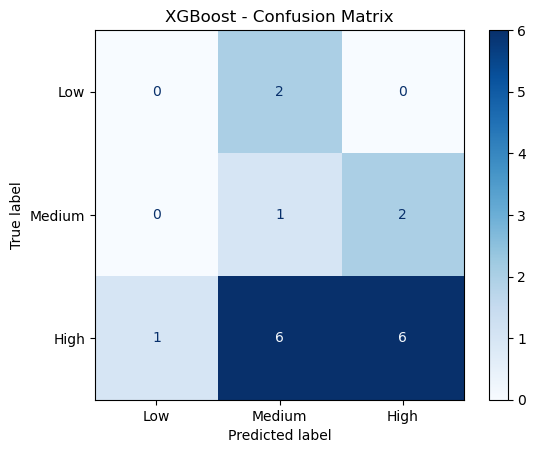

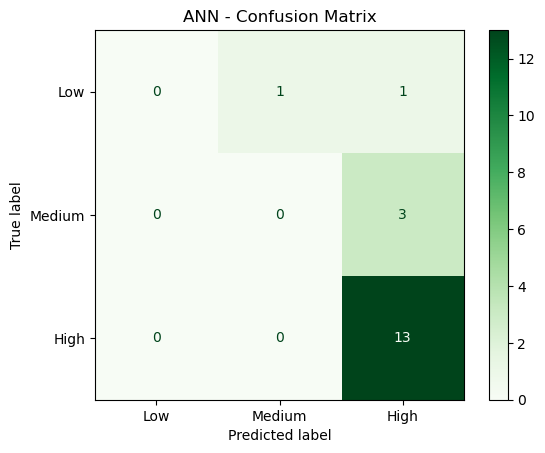

In [16]:
# استيراد أدوات حساب مصفوفة الالتباس وعرضها
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# استيراد مكتبة الرسم
import matplotlib.pyplot as plt

# تحديد ترتيب فئات الطلب الثلاث
class_labels = ['Low', 'Medium', 'High']

# الحصول على تنبؤات XGBoost على بيانات التدريب
xgb_train_predictions = xgb_model.predict(X_train)

# منع ظهور قيم سالبة في تنبؤات التدريب
xgb_train_predictions = np.maximum(xgb_train_predictions, 0)

# تحويل تنبؤات XGBoost التدريبية إلى فئات
xgb_train_class = pd.Series(xgb_train_predictions).apply(classify_demand)

# الحصول على تنبؤات ANN على بيانات التدريب الموحدة
ann_train_predictions_scaled = ann_model.predict(X_train_scaled)

# إعادة تنبؤات ANN التدريبية إلى مقياس عدد الرحلات الأصلي
ann_train_predictions = scaler_y.inverse_transform(
    ann_train_predictions_scaled.reshape(-1, 1)
).ravel()

# منع ظهور قيم سالبة في تنبؤات ANN التدريبية
ann_train_predictions = np.maximum(ann_train_predictions, 0)

# تحويل تنبؤات ANN التدريبية إلى فئات
ann_train_class = pd.Series(ann_train_predictions).apply(classify_demand)

# تحويل قيم التدريب الفعلية إلى فئات
actual_train_class = y_train.apply(classify_demand).reset_index(drop=True)

# تعريف دالة لحساب مقاييس التقييم الأربعة
def calculate_metrics(actual, predicted):
    return {
        'Accuracy': accuracy_score(actual, predicted),
        'Precision': precision_score(
            actual, predicted,
            labels=class_labels,
            average='macro',
            zero_division=0
        ),
        'Recall': recall_score(
            actual, predicted,
            labels=class_labels,
            average='macro',
            zero_division=0
        ),
        'F1-Score': f1_score(
            actual, predicted,
            labels=class_labels,
            average='macro',
            zero_division=0
        )
    }

# حساب مقاييس XGBoost على بيانات التدريب
xgb_train_metrics = calculate_metrics(
    actual_train_class, xgb_train_class
)

# حساب مقاييس XGBoost على بيانات الاختبار
xgb_test_metrics = calculate_metrics(
    actual_class, xgb_predicted_class
)

# حساب مقاييس ANN على بيانات التدريب
ann_train_metrics = calculate_metrics(
    actual_train_class, ann_train_class
)

# حساب مقاييس ANN على بيانات الاختبار
ann_test_metrics = calculate_metrics(
    actual_class, ann_predicted_class
)

# إنشاء جدول مقارنة التدريب والاختبار للنموذجين
overfitting_results = pd.DataFrame([
    {'Model': 'XGBoost', 'Data': 'Training', **xgb_train_metrics},
    {'Model': 'XGBoost', 'Data': 'Testing', **xgb_test_metrics},
    {'Model': 'ANN', 'Data': 'Training', **ann_train_metrics},
    {'Model': 'ANN', 'Data': 'Testing', **ann_test_metrics}
])

# عرض نتائج المقارنة بين التدريب والاختبار
display(overfitting_results.round(4))

# حساب مصفوفة الالتباس لنموذج XGBoost على الاختبار
xgb_cm = confusion_matrix(
    actual_class, xgb_predicted_class,
    labels=class_labels
)

# حساب مصفوفة الالتباس لنموذج ANN على الاختبار
ann_cm = confusion_matrix(
    actual_class, ann_predicted_class,
    labels=class_labels
)

# إنشاء رسم لمصفوفة الالتباس الخاصة بـ XGBoost
ConfusionMatrixDisplay(
    confusion_matrix=xgb_cm,
    display_labels=class_labels
).plot(cmap='Blues', values_format='d')

# إضافة عنوان للرسم الأول
plt.title('XGBoost - Confusion Matrix')

# عرض الرسم الأول
plt.show()

# إنشاء رسم لمصفوفة الالتباس الخاصة بـ ANN
ConfusionMatrixDisplay(
    confusion_matrix=ann_cm,
    display_labels=class_labels
).plot(cmap='Greens', values_format='d')

# إضافة عنوان للرسم الثاني
plt.title('ANN - Confusion Matrix')

# عرض الرسم الثاني
plt.show()

In [17]:
# إنشاء جدول يوضح نتائج تصنيف XGBoost
xgb_confusion_table = pd.DataFrame(
    xgb_cm,
    index=['Actual Low', 'Actual Medium', 'Actual High'],
    columns=['Predicted Low', 'Predicted Medium', 'Predicted High']
)

# إنشاء جدول يوضح نتائج تصنيف ANN
ann_confusion_table = pd.DataFrame(
    ann_cm,
    index=['Actual Low', 'Actual Medium', 'Actual High'],
    columns=['Predicted Low', 'Predicted Medium', 'Predicted High']
)

# عرض مصفوفة الالتباس الخاصة بـ XGBoost
print("XGBoost Confusion Matrix:")
display(xgb_confusion_table)

# عرض مصفوفة الالتباس الخاصة بـ ANN
print("ANN Confusion Matrix:")
display(ann_confusion_table)

# عرض توزيع الفئات الفعلية في بيانات الاختبار
print("Actual Test Class Distribution:")
display(actual_class.value_counts().reindex(class_labels, fill_value=0))

# عرض توزيع الفئات التي توقعها XGBoost
print("XGBoost Predicted Class Distribution:")
display(xgb_predicted_class.value_counts().reindex(class_labels, fill_value=0))

# عرض توزيع الفئات التي توقعها ANN
print("ANN Predicted Class Distribution:")
display(ann_predicted_class.value_counts().reindex(class_labels, fill_value=0))

XGBoost Confusion Matrix:


,Predicted Low,Predicted Medium,Predicted High
Actual Low,0,2,0
Actual Medium,0,1,2
Actual High,1,6,6


ANN Confusion Matrix:


,Predicted Low,Predicted Medium,Predicted High
Actual Low,0,1,1
Actual Medium,0,0,3
Actual High,0,0,13


Actual Test Class Distribution:


TOTAL_DEPARTURES
Low        2
Medium     3
High      13
Name: count, dtype: int64

XGBoost Predicted Class Distribution:


Low       1
Medium    9
High      8
Name: count, dtype: int64

ANN Predicted Class Distribution:


Low        0
Medium     1
High      17
Name: count, dtype: int64

,Model,Data,MAE,RMSE
0,XGBoost,Training,21307.15,33625.78
1,XGBoost,Testing,55410.67,67034.64
2,ANN,Training,13409.96,28026.39
3,ANN,Testing,67656.27,76725.13


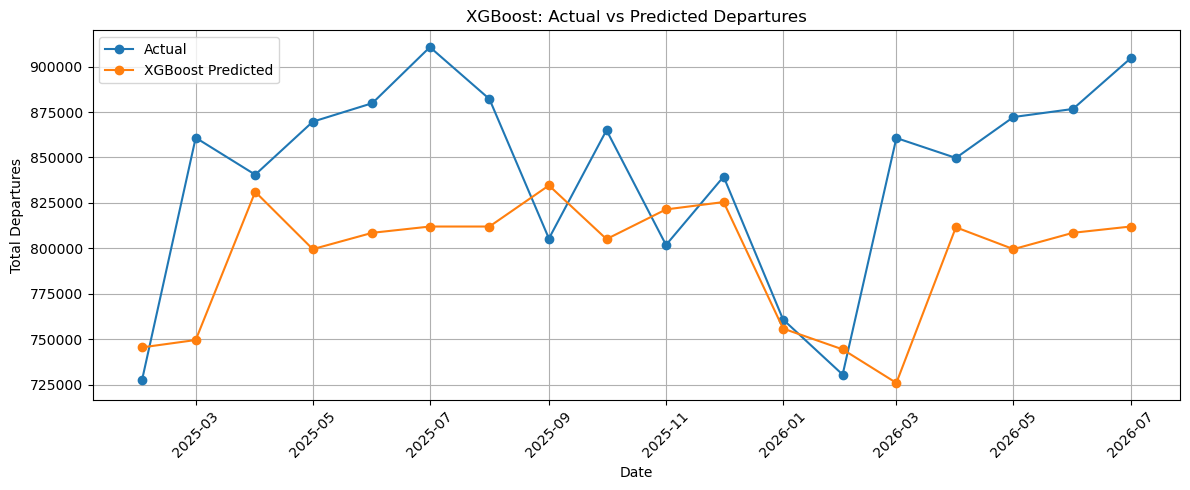

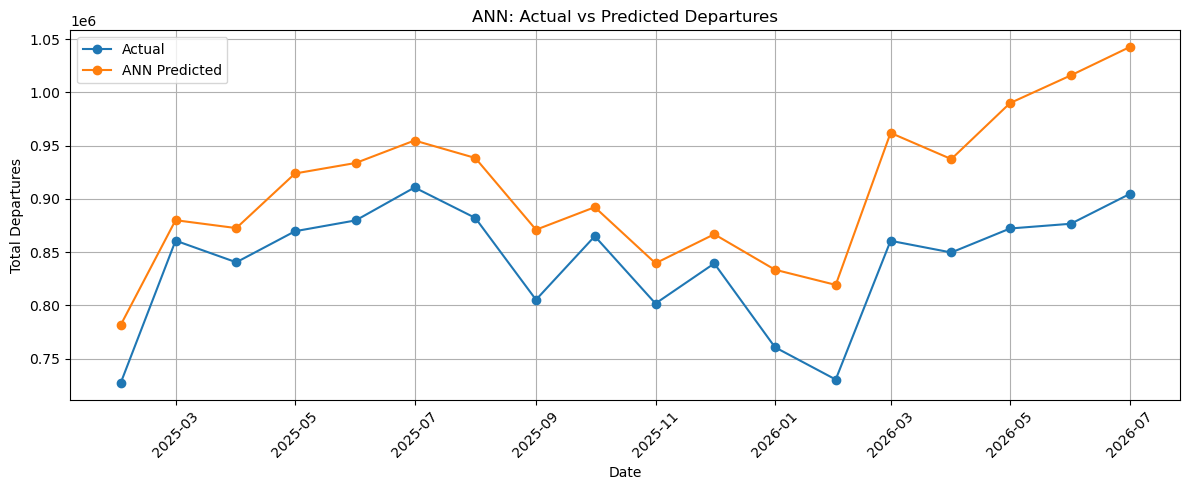

In [18]:
# استيراد مقاييس حساب أخطاء التنبؤ الرقمي
from sklearn.metrics import mean_absolute_error, mean_squared_error

# الحصول على تنبؤات XGBoost الرقمية لبيانات التدريب
xgb_train_numeric = np.maximum(xgb_model.predict(X_train), 0)

# الحصول على تنبؤات XGBoost الرقمية لبيانات الاختبار
xgb_test_numeric = xgb_predictions

# الحصول على تنبؤات ANN الرقمية لبيانات التدريب
ann_train_numeric_scaled = ann_model.predict(X_train_scaled)

# إعادة تنبؤات ANN التدريبية إلى مقياس عدد الرحلات الأصلي
ann_train_numeric = scaler_y.inverse_transform(
    ann_train_numeric_scaled.reshape(-1, 1)
).ravel()

# منع ظهور قيم سالبة في تنبؤات ANN التدريبية
ann_train_numeric = np.maximum(ann_train_numeric, 0)

# الحصول على تنبؤات ANN الرقمية لبيانات الاختبار
ann_test_numeric = ann_predictions

# إنشاء قائمة لتجميع نتائج أخطاء التنبؤ الرقمي
numeric_results = []

# حساب MAE وRMSE لنموذج XGBoost على التدريب
numeric_results.append({
    'Model': 'XGBoost',
    'Data': 'Training',
    'MAE': mean_absolute_error(y_train, xgb_train_numeric),
    'RMSE': np.sqrt(mean_squared_error(y_train, xgb_train_numeric))
})

# حساب MAE وRMSE لنموذج XGBoost على الاختبار
numeric_results.append({
    'Model': 'XGBoost',
    'Data': 'Testing',
    'MAE': mean_absolute_error(y_test, xgb_test_numeric),
    'RMSE': np.sqrt(mean_squared_error(y_test, xgb_test_numeric))
})

# حساب MAE وRMSE لنموذج ANN على التدريب
numeric_results.append({
    'Model': 'ANN',
    'Data': 'Training',
    'MAE': mean_absolute_error(y_train, ann_train_numeric),
    'RMSE': np.sqrt(mean_squared_error(y_train, ann_train_numeric))
})

# حساب MAE وRMSE لنموذج ANN على الاختبار
numeric_results.append({
    'Model': 'ANN',
    'Data': 'Testing',
    'MAE': mean_absolute_error(y_test, ann_test_numeric),
    'RMSE': np.sqrt(mean_squared_error(y_test, ann_test_numeric))
})

# تحويل نتائج أخطاء التنبؤ إلى جدول
numeric_results_table = pd.DataFrame(numeric_results)

# عرض نتائج أخطاء التنبؤ الرقمي
display(numeric_results_table.round(2))

# إنشاء رسم لمقارنة القيم الفعلية والمتوقعة لنموذج XGBoost
plt.figure(figsize=(12, 5))
plt.plot(test_features['DATE'], y_test, marker='o', label='Actual')
plt.plot(test_features['DATE'], xgb_test_numeric, marker='o', label='XGBoost Predicted')
plt.title('XGBoost: Actual vs Predicted Departures')
plt.xlabel('Date')
plt.ylabel('Total Departures')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# إنشاء رسم لمقارنة القيم الفعلية والمتوقعة لنموذج ANN
plt.figure(figsize=(12, 5))
plt.plot(test_features['DATE'], y_test, marker='o', label='Actual')
plt.plot(test_features['DATE'], ann_test_numeric, marker='o', label='ANN Predicted')
plt.title('ANN: Actual vs Predicted Departures')
plt.xlabel('Date')
plt.ylabel('Total Departures')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [19]:
# استيراد أداة التقسيم الزمني
from sklearn.model_selection import TimeSeriesSplit

# إنشاء ثلاثة تقسيمات زمنية مع تخصيص 12 شهرًا للتحقق في كل تقسيم
time_split = TimeSeriesSplit(n_splits=3, test_size=12)

# إنشاء قائمة لحفظ نتائج التحقق الزمني
cv_results = []

# تكرار عملية التحقق على التقسيمات الزمنية الثلاثة
for fold_number, (train_index, validation_index) in enumerate(
    time_split.split(X_train), start=1
):

    # تحديد خصائص التدريب في التقسيم الحالي
    X_fold_train = X_train.iloc[train_index]

    # تحديد خصائص التحقق في التقسيم الحالي
    X_fold_validation = X_train.iloc[validation_index]

    # تحديد القيم الفعلية للتدريب في التقسيم الحالي
    y_fold_train = y_train.iloc[train_index]

    # تحديد القيم الفعلية للتحقق في التقسيم الحالي
    y_fold_validation = y_train.iloc[validation_index]

    # إنشاء نموذج XGBoost بنفس الإعدادات الحالية
    xgb_cv_model = XGBRegressor(
        objective='reg:squarederror',
        n_estimators=100,
        max_depth=2,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42
    )

    # تدريب نموذج XGBoost على الجزء التدريبي فقط
    xgb_cv_model.fit(X_fold_train, y_fold_train)

    # التنبؤ بقيم الرحلات في فترة التحقق
    xgb_cv_predictions = xgb_cv_model.predict(X_fold_validation)

    # منع القيم السالبة في التنبؤات
    xgb_cv_predictions = np.maximum(xgb_cv_predictions, 0)

    # حساب MAE لنموذج XGBoost في التقسيم الحالي
    xgb_cv_mae = mean_absolute_error(
        y_fold_validation, xgb_cv_predictions
    )

    # حساب RMSE لنموذج XGBoost في التقسيم الحالي
    xgb_cv_rmse = np.sqrt(
        mean_squared_error(y_fold_validation, xgb_cv_predictions)
    )

    # حفظ نتائج XGBoost للتقسيم الحالي
    cv_results.append({
        'Fold': fold_number,
        'Model': 'XGBoost',
        'MAE': xgb_cv_mae,
        'RMSE': xgb_cv_rmse
    })

    # إنشاء أداة توحيد خصائص التدريب لهذا التقسيم
    fold_scaler_X = StandardScaler()

    # توحيد خصائص التدريب باستخدام بيانات التدريب فقط
    X_fold_train_scaled = fold_scaler_X.fit_transform(X_fold_train)

    # توحيد خصائص التحقق باستخدام مقاييس التدريب
    X_fold_validation_scaled = fold_scaler_X.transform(
        X_fold_validation
    )

    # إنشاء أداة توحيد قيم الهدف لهذا التقسيم
    fold_scaler_y = StandardScaler()

    # توحيد قيم التدريب
    y_fold_train_scaled = fold_scaler_y.fit_transform(
        y_fold_train.to_numpy().reshape(-1, 1)
    ).ravel()

    # إنشاء نموذج ANN بنفس البنية والإعدادات الحالية
    ann_cv_model = MLPRegressor(
        hidden_layer_sizes=(16, 8),
        activation='relu',
        solver='adam',
        alpha=0.01,
        learning_rate_init=0.001,
        max_iter=3000,
        random_state=42
    )

    # تدريب ANN على بيانات التدريب الموحدة
    ann_cv_model.fit(
        X_fold_train_scaled,
        y_fold_train_scaled
    )

    # التنبؤ بقيم الرحلات في فترة التحقق
    ann_cv_predictions_scaled = ann_cv_model.predict(
        X_fold_validation_scaled
    )

    # إعادة التنبؤات إلى مقياس عدد الرحلات الأصلي
    ann_cv_predictions = fold_scaler_y.inverse_transform(
        ann_cv_predictions_scaled.reshape(-1, 1)
    ).ravel()

    # منع القيم السالبة في التنبؤات
    ann_cv_predictions = np.maximum(ann_cv_predictions, 0)

    # حساب MAE لنموذج ANN في التقسيم الحالي
    ann_cv_mae = mean_absolute_error(
        y_fold_validation, ann_cv_predictions
    )

    # حساب RMSE لنموذج ANN في التقسيم الحالي
    ann_cv_rmse = np.sqrt(
        mean_squared_error(y_fold_validation, ann_cv_predictions)
    )

    # حفظ نتائج ANN للتقسيم الحالي
    cv_results.append({
        'Fold': fold_number,
        'Model': 'ANN',
        'MAE': ann_cv_mae,
        'RMSE': ann_cv_rmse
    })

# تحويل النتائج إلى جدول
cv_results_table = pd.DataFrame(cv_results)

# عرض نتائج كل تقسيم زمني
display(cv_results_table.round(2))

# حساب متوسط MAE وRMSE لكل نموذج عبر التقسيمات الثلاثة
cv_summary = cv_results_table.groupby('Model')[['MAE', 'RMSE']].mean()

# عرض متوسط نتائج التحقق الزمني
print("Average Time Series Cross-Validation Results:")
display(cv_summary.round(2))

,Fold,Model,MAE,RMSE
0,1,XGBoost,54620.29,59569.18
1,1,ANN,70347.27,81857.16
2,2,XGBoost,44802.05,50456.16
3,2,ANN,21049.52,27170.03
4,3,XGBoost,60738.38,95591.85
5,3,ANN,41865.98,48021.72


Average Time Series Cross-Validation Results:


,MAE,RMSE
Model,,
ANN,44420.92,52349.63
XGBoost,53386.91,68539.06


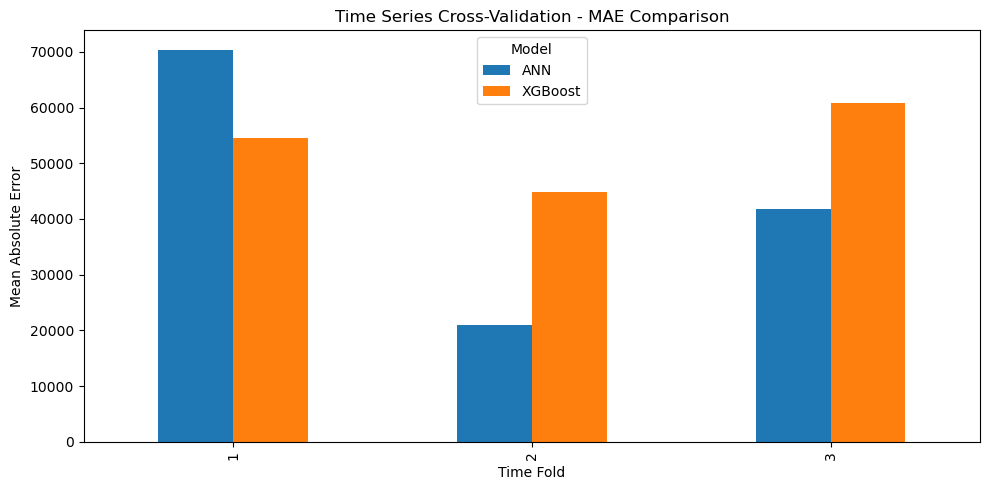

In [20]:
# إنشاء جدول خاص بمتوسط MAE لكل نموذج وتقسيم
cv_mae_pivot = cv_results_table.pivot(
    index='Fold',
    columns='Model',
    values='MAE'
)

# إنشاء رسم لمقارنة MAE عبر التقسيمات الزمنية
cv_mae_pivot.plot(
    kind='bar',
    figsize=(10, 5)
)

# إضافة عنوان الرسم
plt.title('Time Series Cross-Validation - MAE Comparison')

# تسمية المحور الأفقي
plt.xlabel('Time Fold')

# تسمية المحور الرأسي
plt.ylabel('Mean Absolute Error')

# إظهار أسماء النماذج
plt.legend(title='Model')

# تحسين ترتيب عناصر الرسم
plt.tight_layout()

# عرض الرسم
plt.show()

In [21]:
# إنشاء قائمة لحفظ نتائج إعدادات XGBoost المختلفة
xgb_tuning_results = []

# تحديد إعدادات مختلفة لتجربة تقليل تعقيد النموذج
xgb_settings = [
    {'n_estimators': 50, 'max_depth': 1, 'learning_rate': 0.03, 'reg_lambda': 5},
    {'n_estimators': 100, 'max_depth': 1, 'learning_rate': 0.03, 'reg_lambda': 10},
    {'n_estimators': 50, 'max_depth': 2, 'learning_rate': 0.02, 'reg_lambda': 10}
]

# إنشاء ثلاثة تقسيمات زمنية للتحقق من الإعدادات
tuning_split = TimeSeriesSplit(n_splits=3, test_size=12)

# تجربة كل مجموعة من الإعدادات
for setting_number, settings in enumerate(xgb_settings, start=1):

    # إنشاء قائمة لحفظ أخطاء الإعداد الحالي
    fold_mae = []
    fold_rmse = []

    # تنفيذ التحقق الزمني
    for train_index, validation_index in tuning_split.split(X_train):

        # تحديد بيانات التدريب في التقسيم الحالي
        X_fold_train = X_train.iloc[train_index]
        y_fold_train = y_train.iloc[train_index]

        # تحديد بيانات التحقق في التقسيم الحالي
        X_fold_validation = X_train.iloc[validation_index]
        y_fold_validation = y_train.iloc[validation_index]

        # إنشاء نموذج XGBoost بالإعدادات الحالية
        tuning_model = XGBRegressor(
            objective='reg:squarederror',
            n_estimators=settings['n_estimators'],
            max_depth=settings['max_depth'],
            learning_rate=settings['learning_rate'],
            subsample=0.8,
            colsample_bytree=0.8,
            reg_lambda=settings['reg_lambda'],
            random_state=42
        )

        # تدريب النموذج على بيانات التدريب
        tuning_model.fit(X_fold_train, y_fold_train)

        # التنبؤ على بيانات التحقق
        fold_predictions = tuning_model.predict(X_fold_validation)

        # منع التنبؤات السالبة
        fold_predictions = np.maximum(fold_predictions, 0)

        # حساب MAE للتقسيم الحالي
        fold_mae.append(
            mean_absolute_error(y_fold_validation, fold_predictions)
        )

        # حساب RMSE للتقسيم الحالي
        fold_rmse.append(
            np.sqrt(mean_squared_error(y_fold_validation, fold_predictions))
        )

    # حفظ متوسط نتائج الإعداد الحالي
    xgb_tuning_results.append({
        'Setting': setting_number,
        'Parameters': str(settings),
        'Average_MAE': np.mean(fold_mae),
        'Average_RMSE': np.mean(fold_rmse)
    })

# تحويل نتائج التجارب إلى جدول
xgb_tuning_table = pd.DataFrame(xgb_tuning_results)

# عرض نتائج إعدادات XGBoost
display(xgb_tuning_table.round(2))

,Setting,Parameters,Average_MAE,Average_RMSE
0,1,"{'n_estimators': 50, 'max_depth': 1, 'learning...",79334.94,89950.69
1,2,"{'n_estimators': 100, 'max_depth': 1, 'learnin...",63403.22,76682.04
2,3,"{'n_estimators': 50, 'max_depth': 2, 'learning...",92735.72,101085.25


In [22]:
# إنشاء قائمة لحفظ نتائج تجارب ANN
ann_tuning_results = []

# تحديد إعدادات مختلفة للشبكة العصبية
ann_settings = [
    {'hidden_layer_sizes': (8,), 'alpha': 0.1},
    {'hidden_layer_sizes': (8, 4), 'alpha': 0.1},
    {'hidden_layer_sizes': (16,), 'alpha': 0.5}
]

# إنشاء تقسيمات التحقق الزمني نفسها
ann_tuning_split = TimeSeriesSplit(n_splits=3, test_size=12)

# تجربة إعدادات ANN المختلفة
for setting_number, settings in enumerate(ann_settings, start=1):

    # إنشاء قوائم لحفظ أخطاء كل تقسيم
    fold_mae = []
    fold_rmse = []

    # تنفيذ التحقق الزمني
    for train_index, validation_index in ann_tuning_split.split(X_train):

        # تحديد بيانات التدريب في التقسيم الحالي
        X_fold_train = X_train.iloc[train_index]
        y_fold_train = y_train.iloc[train_index]

        # تحديد بيانات التحقق في التقسيم الحالي
        X_fold_validation = X_train.iloc[validation_index]
        y_fold_validation = y_train.iloc[validation_index]

        # إنشاء أداة توحيد خصائص التدريب
        fold_scaler_X = StandardScaler()

        # توحيد خصائص التدريب
        X_fold_train_scaled = fold_scaler_X.fit_transform(X_fold_train)

        # توحيد خصائص التحقق باستخدام مقاييس التدريب
        X_fold_validation_scaled = fold_scaler_X.transform(
            X_fold_validation
        )

        # إنشاء أداة توحيد قيم الهدف
        fold_scaler_y = StandardScaler()

        # توحيد قيم الهدف في التدريب
        y_fold_train_scaled = fold_scaler_y.fit_transform(
            y_fold_train.to_numpy().reshape(-1, 1)
        ).ravel()

        # إنشاء نموذج ANN بالإعدادات الحالية
        tuning_ann = MLPRegressor(
            hidden_layer_sizes=settings['hidden_layer_sizes'],
            activation='relu',
            solver='adam',
            alpha=settings['alpha'],
            learning_rate_init=0.001,
            max_iter=3000,
            random_state=42
        )

        # تدريب نموذج ANN
        tuning_ann.fit(X_fold_train_scaled, y_fold_train_scaled)

        # التنبؤ على بيانات التحقق
        fold_predictions_scaled = tuning_ann.predict(
            X_fold_validation_scaled
        )

        # إعادة التنبؤات إلى مقياس عدد الرحلات الأصلي
        fold_predictions = fold_scaler_y.inverse_transform(
            fold_predictions_scaled.reshape(-1, 1)
        ).ravel()

        # منع ظهور قيم سالبة
        fold_predictions = np.maximum(fold_predictions, 0)

        # حساب MAE للتقسيم الحالي
        fold_mae.append(
            mean_absolute_error(y_fold_validation, fold_predictions)
        )

        # حساب RMSE للتقسيم الحالي
        fold_rmse.append(
            np.sqrt(mean_squared_error(y_fold_validation, fold_predictions))
        )

    # حفظ متوسط نتائج الإعداد الحالي
    ann_tuning_results.append({
        'Setting': setting_number,
        'Parameters': str(settings),
        'Average_MAE': np.mean(fold_mae),
        'Average_RMSE': np.mean(fold_rmse)
    })

# تحويل نتائج التجارب إلى جدول
ann_tuning_table = pd.DataFrame(ann_tuning_results)

# عرض نتائج إعدادات ANN
display(ann_tuning_table.round(2))

,Setting,Parameters,Average_MAE,Average_RMSE
0,1,"{'hidden_layer_sizes': (8,), 'alpha': 0.1}",40332.14,48048.88
1,2,"{'hidden_layer_sizes': (8, 4), 'alpha': 0.1}",95229.62,106356.57
2,3,"{'hidden_layer_sizes': (16,), 'alpha': 0.5}",39978.19,46138.03


In [23]:
# إنشاء أداة توحيد خصائص التدريب للنموذج المحسّن
final_ann_scaler_X = StandardScaler()

# توحيد خصائص التدريب وحساب مقاييس التوحيد منها
X_train_final_scaled = final_ann_scaler_X.fit_transform(X_train)

# توحيد خصائص الاختبار باستخدام مقاييس التدريب
X_test_final_scaled = final_ann_scaler_X.transform(X_test)

# إنشاء أداة توحيد قيم الهدف
final_ann_scaler_y = StandardScaler()

# توحيد قيم الهدف في بيانات التدريب
y_train_final_scaled = final_ann_scaler_y.fit_transform(
    y_train.to_numpy().reshape(-1, 1)
).ravel()

# إنشاء نموذج ANN بالإعدادات الأفضل التي اخترناها
final_ann_model = MLPRegressor(
    hidden_layer_sizes=(16,),
    activation='relu',
    solver='adam',
    alpha=0.5,
    learning_rate_init=0.001,
    max_iter=3000,
    random_state=42
)

# تدريب نموذج ANN المحسّن على كامل بيانات التدريب
final_ann_model.fit(X_train_final_scaled, y_train_final_scaled)

# التنبؤ بعدد الرحلات في بيانات الاختبار
final_ann_predictions_scaled = final_ann_model.predict(
    X_test_final_scaled
)

# إعادة التنبؤات إلى مقياس عدد الرحلات الأصلي
final_ann_predictions = final_ann_scaler_y.inverse_transform(
    final_ann_predictions_scaled.reshape(-1, 1)
).ravel()

# منع ظهور قيم سالبة في التنبؤات
final_ann_predictions = np.maximum(final_ann_predictions, 0)

# حساب MAE للنموذج المحسّن على بيانات الاختبار
final_ann_mae = mean_absolute_error(y_test, final_ann_predictions)

# حساب RMSE للنموذج المحسّن على بيانات الاختبار
final_ann_rmse = np.sqrt(
    mean_squared_error(y_test, final_ann_predictions)
)

# تحويل التنبؤات الرقمية إلى فئات الطلب
final_ann_predicted_class = pd.Series(
    final_ann_predictions
).apply(classify_demand)

# حساب Accuracy للنموذج المحسّن
final_ann_accuracy = accuracy_score(
    actual_class, final_ann_predicted_class
)

# حساب Precision للنموذج المحسّن
final_ann_precision = precision_score(
    actual_class,
    final_ann_predicted_class,
    labels=class_labels,
    average='macro',
    zero_division=0
)

# حساب Recall للنموذج المحسّن
final_ann_recall = recall_score(
    actual_class,
    final_ann_predicted_class,
    labels=class_labels,
    average='macro',
    zero_division=0
)

# حساب F1-Score للنموذج المحسّن
final_ann_f1 = f1_score(
    actual_class,
    final_ann_predicted_class,
    labels=class_labels,
    average='macro',
    zero_division=0
)

# إنشاء جدول نتائج ANN المحسّن
final_ann_results = pd.DataFrame({
    'Model': ['ANN Improved'],
    'MAE': [final_ann_mae],
    'RMSE': [final_ann_rmse],
    'Accuracy': [final_ann_accuracy],
    'Precision': [final_ann_precision],
    'Recall': [final_ann_recall],
    'F1-Score': [final_ann_f1]
})

# عرض نتائج النموذج المحسّن
display(final_ann_results.round(4))

,Model,MAE,RMSE,Accuracy,Precision,Recall,F1-Score
0,ANN Improved,40504.2589,46504.8555,0.6111,0.6616,0.5085,0.5463


In [24]:
# تحديد ترتيب فئات الطلب
class_labels = ['Low', 'Medium', 'High']

# التنبؤ ببيانات التدريب لقياس أداء النموذج عليها
train_ann_predictions_scaled = final_ann_model.predict(
    X_train_final_scaled
)

# إعادة التنبؤات إلى مقياس عدد الرحلات الأصلي
train_ann_predictions = final_ann_scaler_y.inverse_transform(
    train_ann_predictions_scaled.reshape(-1, 1)
).ravel()

# منع القيم السالبة
train_ann_predictions = np.maximum(train_ann_predictions, 0)

# تحويل التنبؤات الرقمية في التدريب إلى فئات
train_ann_predicted_class = pd.Series(
    train_ann_predictions
).apply(classify_demand)

# تحويل القيم الفعلية في التدريب إلى فئات
train_actual_class = y_train.reset_index(drop=True).apply(
    classify_demand
)

# حساب أخطاء التنبؤ الرقمي في التدريب
train_mae = mean_absolute_error(
    y_train, train_ann_predictions
)

train_rmse = np.sqrt(
    mean_squared_error(y_train, train_ann_predictions)
)

# حساب أخطاء التنبؤ الرقمي في الاختبار
test_mae = mean_absolute_error(
    y_test, final_ann_predictions
)

test_rmse = np.sqrt(
    mean_squared_error(y_test, final_ann_predictions)
)

# إنشاء جدول مقارنة أخطاء التدريب والاختبار
overfitting_check = pd.DataFrame({
    'Dataset': ['Training', 'Testing'],
    'MAE': [train_mae, test_mae],
    'RMSE': [train_rmse, test_rmse]
})

# حساب مصفوفة الالتباس للاختبار
ann_improved_cm = confusion_matrix(
    actual_class,
    final_ann_predicted_class,
    labels=class_labels
)

# عرض توزيع الفئات الفعلية والمتوقعة في الاختبار
class_distribution = pd.DataFrame({
    'Actual': actual_class.value_counts().reindex(
        class_labels, fill_value=0
    ),
    'Predicted': final_ann_predicted_class.value_counts().reindex(
        class_labels, fill_value=0
    )
})

print("Training vs Testing Errors:")
display(overfitting_check.round(2))

print("Actual vs Predicted Class Distribution:")
display(class_distribution)

print("ANN Improved Confusion Matrix:")
display(pd.DataFrame(
    ann_improved_cm,
    index=[f'Actual {c}' for c in class_labels],
    columns=[f'Predicted {c}' for c in class_labels]
))

Training vs Testing Errors:


,Dataset,MAE,RMSE
0,Training,30986.32,51590.79
1,Testing,40504.26,46504.86


Actual vs Predicted Class Distribution:


,Actual,Predicted
Low,2,1
Medium,3,6
High,13,11


ANN Improved Confusion Matrix:


,Predicted Low,Predicted Medium,Predicted High
Actual Low,1,1,0
Actual Medium,0,1,2
Actual High,0,4,9


Final Model Comparison


,Model,MAE,RMSE,Accuracy,Precision,Recall,F1-Score
0,XGBoost,55410.6701,67034.6444,0.3889,0.2870,0.2650,0.2460
1,ANN Improved,40504.2589,46504.8555,0.6111,0.6616,0.5085,0.5463


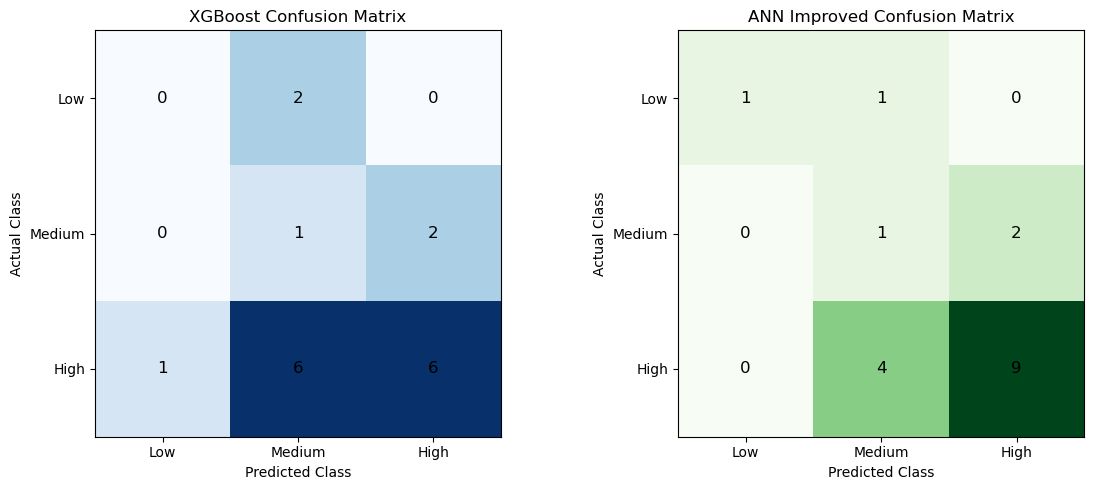

In [25]:
# تحديد ترتيب فئات الطلب
class_labels = ['Low', 'Medium', 'High']

# تحويل تنبؤات XGBoost الرقمية إلى فئات
xgb_final_classes = pd.Series(xgb_predictions).apply(classify_demand)

# تحويل تنبؤات ANN المحسّن الرقمية إلى فئات
ann_final_classes = pd.Series(final_ann_predictions).apply(classify_demand)

# حساب مقاييس XGBoost
xgb_mae = mean_absolute_error(y_test, xgb_predictions)
xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_predictions))
xgb_accuracy = accuracy_score(actual_class, xgb_final_classes)

xgb_precision = precision_score(
    actual_class, xgb_final_classes,
    labels=class_labels, average='macro', zero_division=0
)

xgb_recall = recall_score(
    actual_class, xgb_final_classes,
    labels=class_labels, average='macro', zero_division=0
)

xgb_f1 = f1_score(
    actual_class, xgb_final_classes,
    labels=class_labels, average='macro', zero_division=0
)

# إنشاء جدول المقارنة النهائي
final_comparison = pd.DataFrame({
    'Model': ['XGBoost', 'ANN Improved'],
    'MAE': [xgb_mae, final_ann_mae],
    'RMSE': [xgb_rmse, final_ann_rmse],
    'Accuracy': [xgb_accuracy, final_ann_accuracy],
    'Precision': [xgb_precision, final_ann_precision],
    'Recall': [xgb_recall, final_ann_recall],
    'F1-Score': [xgb_f1, final_ann_f1]
})

# عرض جدول المقارنة
print("Final Model Comparison")
display(final_comparison.round(4))

# حساب مصفوفة الالتباس لكل نموذج
xgb_cm = confusion_matrix(
    actual_class, xgb_final_classes, labels=class_labels
)

ann_cm = confusion_matrix(
    actual_class, ann_final_classes, labels=class_labels
)

# إنشاء رسم يحتوي على مصفوفتَي الالتباس
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# رسم مصفوفة XGBoost
axes[0].imshow(xgb_cm, cmap='Blues')
axes[0].set_title('XGBoost Confusion Matrix')
axes[0].set_xticks(range(3))
axes[0].set_yticks(range(3))
axes[0].set_xticklabels(class_labels)
axes[0].set_yticklabels(class_labels)
axes[0].set_xlabel('Predicted Class')
axes[0].set_ylabel('Actual Class')

for i in range(3):
    for j in range(3):
        axes[0].text(j, i, xgb_cm[i, j],
                     ha='center', va='center', fontsize=12)

# رسم مصفوفة ANN المحسّن
axes[1].imshow(ann_cm, cmap='Greens')
axes[1].set_title('ANN Improved Confusion Matrix')
axes[1].set_xticks(range(3))
axes[1].set_yticks(range(3))
axes[1].set_xticklabels(class_labels)
axes[1].set_yticklabels(class_labels)
axes[1].set_xlabel('Predicted Class')
axes[1].set_ylabel('Actual Class')

for i in range(3):
    for j in range(3):
        axes[1].text(j, i, ann_cm[i, j],
                     ha='center', va='center', fontsize=12)

plt.tight_layout()
plt.show()

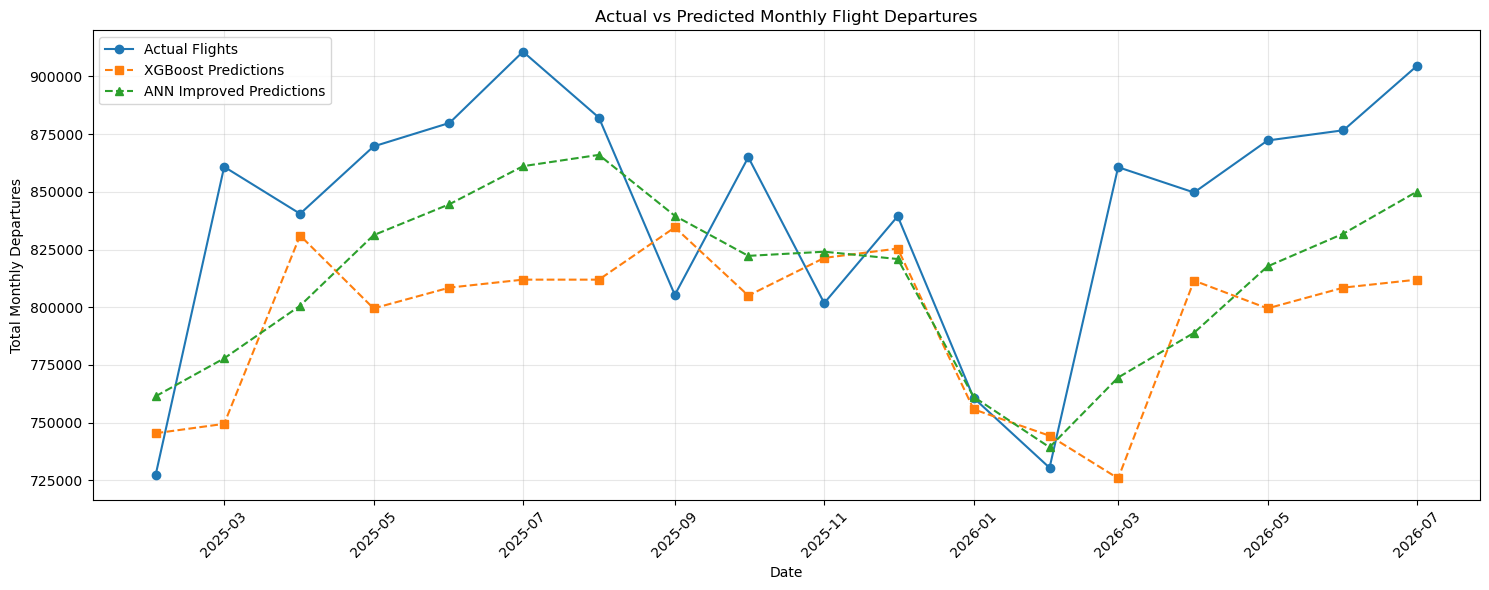

In [26]:
# إنشاء جدول يجمع التاريخ والقيم الفعلية وتوقعات النموذجين
comparison_plot = pd.DataFrame({
    'Date': test_data['DATE'].reset_index(drop=True),
    'Actual': y_test.reset_index(drop=True),
    'XGBoost': xgb_predictions,
    'ANN Improved': final_ann_predictions
})

# إنشاء حجم الرسم
plt.figure(figsize=(15, 6))

# رسم القيم الفعلية
plt.plot(
    comparison_plot['Date'],
    comparison_plot['Actual'],
    marker='o',
    label='Actual Flights'
)

# رسم توقعات XGBoost
plt.plot(
    comparison_plot['Date'],
    comparison_plot['XGBoost'],
    marker='s',
    linestyle='--',
    label='XGBoost Predictions'
)

# رسم توقعات ANN المحسّن
plt.plot(
    comparison_plot['Date'],
    comparison_plot['ANN Improved'],
    marker='^',
    linestyle='--',
    label='ANN Improved Predictions'
)

# إضافة عنوان الرسم وتسميات المحاور
plt.title('Actual vs Predicted Monthly Flight Departures')
plt.xlabel('Date')
plt.ylabel('Total Monthly Departures')

# إظهار وسيلة الإيضاح والشبكة
plt.legend()
plt.grid(True, alpha=0.3)

# تحسين تنسيق التاريخ
plt.xticks(rotation=45)

# ضبط المسافات وعرض الرسم
plt.tight_layout()
plt.show()

In [27]:
# عرض أول خمسة أشهر من المقارنة
print("First 5 Months:")
display(comparison_plot.head().round(2))

# عرض آخر خمسة أشهر من المقارنة
print("Last 5 Months:")
display(comparison_plot.tail().round(2))

# حساب متوسط القيم الفعلية والمتوقعة
print("Average Monthly Departures:")

display(comparison_plot[
    ['Actual', 'XGBoost', 'ANN Improved']
].mean().round(2))

# حساب متوسط الخطأ المطلق لكل نموذج
print("Average Absolute Error:")

display(pd.DataFrame({
    'Model': ['XGBoost', 'ANN Improved'],
    'Average Absolute Error': [
        mean_absolute_error(
            comparison_plot['Actual'],
            comparison_plot['XGBoost']
        ),
        mean_absolute_error(
            comparison_plot['Actual'],
            comparison_plot['ANN Improved']
        )
    ]
}).round(2))

First 5 Months:


/var/folders/hw/8swtb_bn5xv82r5f3jw9xz2w0000gp/T/ipykernel_1579/1388632285.py:3: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(comparison_plot.head().round(2))


,Date,Actual,XGBoost,ANN Improved
0,2025-02-01,727273.0,745429.2500,761423.47
1,2025-03-01,860838.0,749497.1250,777868.55
2,2025-04-01,840502.0,831070.3750,800658.85
3,2025-05-01,869674.0,799509.6875,831223.18
4,2025-06-01,879848.0,808510.3125,844646.79


Last 5 Months:


/var/folders/hw/8swtb_bn5xv82r5f3jw9xz2w0000gp/T/ipykernel_1579/1388632285.py:7: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(comparison_plot.tail().round(2))


,Date,Actual,XGBoost,ANN Improved
13,2026-03-01,860680.0,725872.8750,769561.86
14,2026-04-01,849710.0,811542.3750,788947.79
15,2026-05-01,872235.0,799509.6875,817697.97
16,2026-06-01,876674.0,808510.3125,831908.62
17,2026-07-01,904540.0,811960.0000,850106.48


Average Monthly Departures:


Actual          840979.22
XGBoost         794550.88
ANN Improved    811586.25
dtype: float64

Average Absolute Error:


,Model,Average Absolute Error
0,XGBoost,55410.67
1,ANN Improved,40504.26


In [28]:
# فحص عدد القيم المختلفة في تنبؤات كل نموذج
print("XGBoost unique predictions:")
print(pd.Series(xgb_predictions).nunique())

print("\nANN unique predictions:")
print(pd.Series(final_ann_predictions).nunique())

# عرض التوقعات مع القيم الفعلية
display(
    comparison_plot[
        ['Date', 'Actual', 'XGBoost', 'ANN Improved']
    ].round(2)
)

XGBoost unique predictions:
14

ANN unique predictions:
18


/var/folders/hw/8swtb_bn5xv82r5f3jw9xz2w0000gp/T/ipykernel_1579/2044682141.py:12: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(2)


,Date,Actual,XGBoost,ANN Improved
0,2025-02-01,727273.0,745429.2500,761423.47
1,2025-03-01,860838.0,749497.1250,777868.55
2,2025-04-01,840502.0,831070.3750,800658.85
3,2025-05-01,869674.0,799509.6875,831223.18
4,2025-06-01,879848.0,808510.3125,844646.79
5,2025-07-01,910713.0,811960.0000,861113.17
6,2025-08-01,882153.0,811960.0000,866006.08
7,2025-09-01,805351.0,834587.8125,839619.04
8,2025-10-01,864979.0,805045.1250,822261.04
9,2025-11-01,801810.0,821377.0625,824059.43


In [29]:
# إنشاء أداة التقسيم الزمني إلى 3 أجزاء
stability_split = TimeSeriesSplit(
    n_splits=3,
    test_size=12
)

# إنشاء قائمة لتخزين نتائج المقارنة
stability_results = []

# المرور على التقسيمات الزمنية الثلاثة
for fold, (train_idx, val_idx) in enumerate(
    stability_split.split(X_train), start=1
):

    # تحديد بيانات التدريب والتحقق لهذا التقسيم
    X_fold_train = X_train.iloc[train_idx]
    X_fold_val = X_train.iloc[val_idx]

    y_fold_train = y_train.iloc[train_idx]
    y_fold_val = y_train.iloc[val_idx]

    # -------------------------------
    # أولاً: تدريب XGBoost الأصلي
    # -------------------------------

    xgb_fold = XGBRegressor(
        objective='reg:squarederror',
        n_estimators=100,
        max_depth=2,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42
    )

    # تدريب النموذج
    xgb_fold.fit(X_fold_train, y_fold_train)

    # التنبؤ على بيانات التحقق
    xgb_fold_pred = xgb_fold.predict(X_fold_val)

    # منع القيم السالبة
    xgb_fold_pred = np.maximum(xgb_fold_pred, 0)

    # حساب أخطاء XGBoost
    xgb_fold_mae = mean_absolute_error(
        y_fold_val, xgb_fold_pred
    )

    xgb_fold_rmse = np.sqrt(
        mean_squared_error(y_fold_val, xgb_fold_pred)
    )

    # حفظ نتائج XGBoost
    stability_results.append({
        'Fold': fold,
        'Model': 'XGBoost',
        'MAE': xgb_fold_mae,
        'RMSE': xgb_fold_rmse
    })

    # -------------------------------
    # ثانياً: تدريب ANN المحسّن
    # -------------------------------

    # توحيد خصائص التدريب والتحقق
    fold_scaler_X = StandardScaler()

    X_fold_train_scaled = fold_scaler_X.fit_transform(
        X_fold_train
    )

    X_fold_val_scaled = fold_scaler_X.transform(
        X_fold_val
    )

    # توحيد قيم الهدف اعتماداً على التدريب فقط
    fold_scaler_y = StandardScaler()

    y_fold_train_scaled = fold_scaler_y.fit_transform(
        y_fold_train.to_numpy().reshape(-1, 1)
    ).ravel()

    # إنشاء ANN بالإعدادات المحسّنة
    ann_fold = MLPRegressor(
        hidden_layer_sizes=(16,),
        activation='relu',
        solver='adam',
        alpha=0.5,
        learning_rate_init=0.001,
        max_iter=3000,
        random_state=42
    )

    # تدريب ANN
    ann_fold.fit(
        X_fold_train_scaled,
        y_fold_train_scaled
    )

    # التنبؤ على بيانات التحقق
    ann_fold_pred_scaled = ann_fold.predict(
        X_fold_val_scaled
    )

    # إعادة التنبؤات إلى مقياس عدد الرحلات
    ann_fold_pred = fold_scaler_y.inverse_transform(
        ann_fold_pred_scaled.reshape(-1, 1)
    ).ravel()

    # منع القيم السالبة
    ann_fold_pred = np.maximum(ann_fold_pred, 0)

    # حساب أخطاء ANN
    ann_fold_mae = mean_absolute_error(
        y_fold_val, ann_fold_pred
    )

    ann_fold_rmse = np.sqrt(
        mean_squared_error(y_fold_val, ann_fold_pred)
    )

    # حفظ نتائج ANN
    stability_results.append({
        'Fold': fold,
        'Model': 'ANN Improved',
        'MAE': ann_fold_mae,
        'RMSE': ann_fold_rmse
    })

# تحويل النتائج إلى جدول
stability_table = pd.DataFrame(stability_results)

# عرض نتائج كل تقسيم
print("Time Series Cross-Validation Results:")
display(stability_table.round(2))

# حساب متوسط الأخطاء لكل نموذج
stability_summary = stability_table.groupby('Model')[
    ['MAE', 'RMSE']
].mean().reset_index()

# عرض المتوسط النهائي
print("Average Cross-Validation Results:")
display(stability_summary.round(2))

Time Series Cross-Validation Results:


,Fold,Model,MAE,RMSE
0,1,XGBoost,54620.29,59569.18
1,1,ANN Improved,62505.03,72315.22
2,2,XGBoost,44802.05,50456.16
3,2,ANN Improved,27487.04,31951.76
4,3,XGBoost,60738.38,95591.85
5,3,ANN Improved,29942.50,34147.12


Average Cross-Validation Results:


,Model,MAE,RMSE
0,ANN Improved,39978.19,46138.03
1,XGBoost,53386.91,68539.06


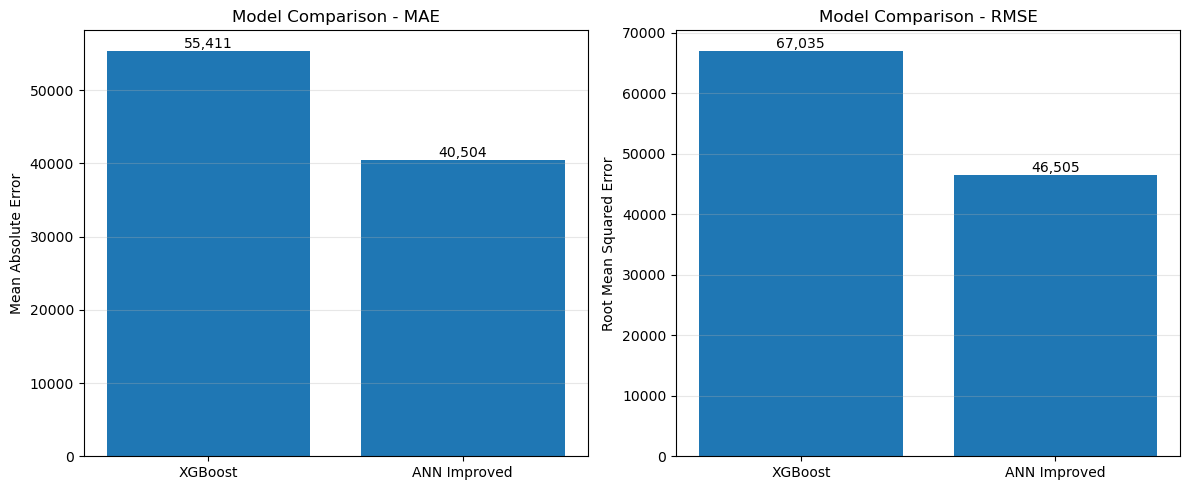

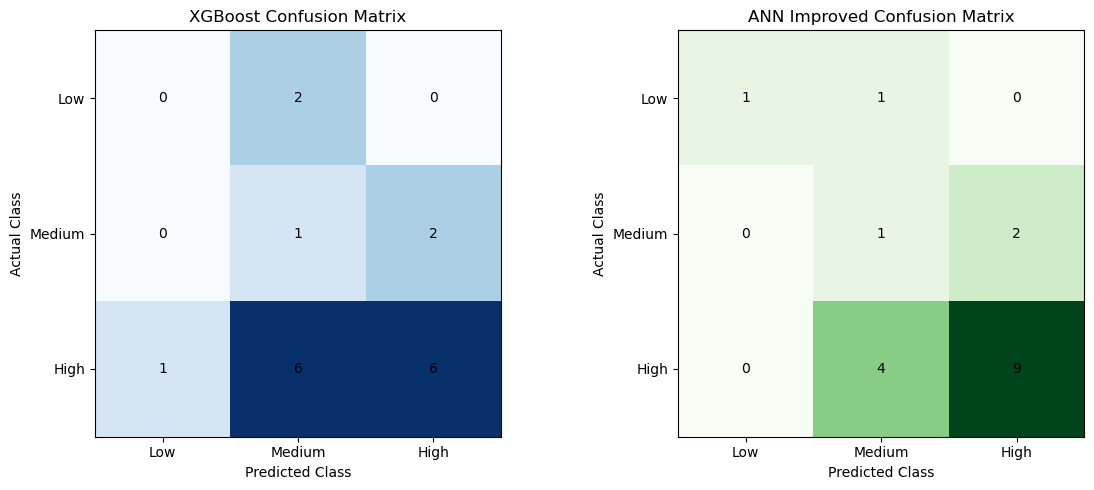

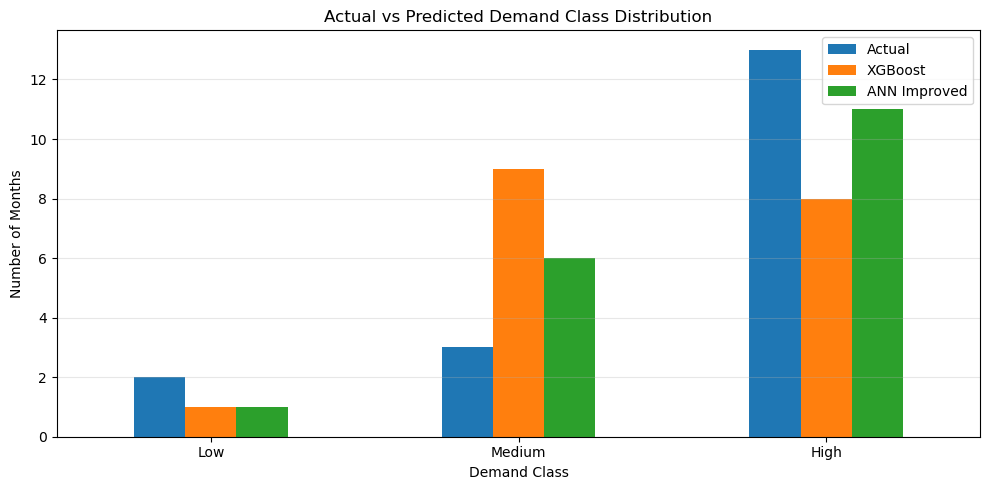

Demand Class Distribution:


,Actual,XGBoost,ANN Improved
Low,2,1,1
Medium,3,9,6
High,13,8,11


In [30]:
# تحديد أسماء النماذج وفئات الطلب
models = ['XGBoost', 'ANN Improved']
class_labels = ['Low', 'Medium', 'High']

# ==================================================
# الرسم الأول: مقارنة MAE و RMSE
# ==================================================

# استخراج قيم MAE و RMSE من جدول المقارنة النهائي
mae_values = final_comparison['MAE'].values
rmse_values = final_comparison['RMSE'].values

# إنشاء مساحة الرسم
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# رسم مقارنة MAE
axes[0].bar(models, mae_values)
axes[0].set_title('Model Comparison - MAE')
axes[0].set_ylabel('Mean Absolute Error')
axes[0].grid(axis='y', alpha=0.3)

# كتابة قيمة كل عمود
for i, value in enumerate(mae_values):
    axes[0].text(i, value, f'{value:,.0f}',
                 ha='center', va='bottom')

# رسم مقارنة RMSE
axes[1].bar(models, rmse_values)
axes[1].set_title('Model Comparison - RMSE')
axes[1].set_ylabel('Root Mean Squared Error')
axes[1].grid(axis='y', alpha=0.3)

# كتابة قيمة كل عمود
for i, value in enumerate(rmse_values):
    axes[1].text(i, value, f'{value:,.0f}',
                 ha='center', va='bottom')

plt.tight_layout()
plt.show()


# ==================================================
# الرسم الثاني: مصفوفات الالتباس
# ==================================================

# حساب مصفوفة الالتباس لـ XGBoost
xgb_cm = confusion_matrix(
    actual_class,
    xgb_final_classes,
    labels=class_labels
)

# حساب مصفوفة الالتباس لـ ANN المحسّن
ann_cm = confusion_matrix(
    actual_class,
    ann_final_classes,
    labels=class_labels
)

# إنشاء رسم بمصفوفتين
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# رسم XGBoost
axes[0].imshow(xgb_cm, cmap='Blues')
axes[0].set_title('XGBoost Confusion Matrix')
axes[0].set_xlabel('Predicted Class')
axes[0].set_ylabel('Actual Class')
axes[0].set_xticks(range(3))
axes[0].set_yticks(range(3))
axes[0].set_xticklabels(class_labels)
axes[0].set_yticklabels(class_labels)

for i in range(3):
    for j in range(3):
        axes[0].text(
            j, i, xgb_cm[i, j],
            ha='center', va='center'
        )

# رسم ANN المحسّن
axes[1].imshow(ann_cm, cmap='Greens')
axes[1].set_title('ANN Improved Confusion Matrix')
axes[1].set_xlabel('Predicted Class')
axes[1].set_ylabel('Actual Class')
axes[1].set_xticks(range(3))
axes[1].set_yticks(range(3))
axes[1].set_xticklabels(class_labels)
axes[1].set_yticklabels(class_labels)

for i in range(3):
    for j in range(3):
        axes[1].text(
            j, i, ann_cm[i, j],
            ha='center', va='center'
        )

plt.tight_layout()
plt.show()


# ==================================================
# الرسم الثالث: توزيع الفئات الفعلية والمتوقعة
# ==================================================

# حساب عدد الحالات الفعلية لكل فئة
actual_counts = actual_class.value_counts().reindex(
    class_labels, fill_value=0
)

# حساب عدد توقعات XGBoost لكل فئة
xgb_counts = xgb_final_classes.value_counts().reindex(
    class_labels, fill_value=0
)

# حساب عدد توقعات ANN لكل فئة
ann_counts = ann_final_classes.value_counts().reindex(
    class_labels, fill_value=0
)

# إنشاء جدول توزيع الفئات
distribution = pd.DataFrame({
    'Actual': actual_counts,
    'XGBoost': xgb_counts,
    'ANN Improved': ann_counts
})

# رسم توزيع الفئات
distribution.plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Actual vs Predicted Demand Class Distribution')
plt.xlabel('Demand Class')
plt.ylabel('Number of Months')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# عرض جدول التوزيع بالأرقام
print("Demand Class Distribution:")
display(distribution)

In [31]:
# حفظ النماذج والبيانات اللازمة لتشغيل الواجهة الرسومية

import os
import joblib
import pandas as pd

# إنشاء مجلد لحفظ ملفات النظام
os.makedirs("flight_prediction_artifacts", exist_ok=True)

# حفظ نموذج XGBoost
joblib.dump(
    xgb_model,
    "flight_prediction_artifacts/xgb_model.pkl"
)

# حفظ نموذج ANN المحسّن
joblib.dump(
    final_ann_model,
    "flight_prediction_artifacts/final_ann_model.pkl"
)

# حفظ أدوات التوحيد الخاصة بنموذج ANN
joblib.dump(
    final_ann_scaler_X,
    "flight_prediction_artifacts/final_ann_scaler_X.pkl"
)

joblib.dump(
    final_ann_scaler_y,
    "flight_prediction_artifacts/final_ann_scaler_y.pkl"
)

# حفظ ترتيب الخصائص المستخدمة أثناء التدريب
joblib.dump(
    feature_columns,
    "flight_prediction_artifacts/feature_columns.pkl"
)

# حفظ حدود تصنيف مستويات الطلب
joblib.dump(
    {
        "low_threshold": float(low_threshold),
        "high_threshold": float(high_threshold)
    },
    "flight_prediction_artifacts/demand_thresholds.pkl"
)

# حفظ البيانات الشهرية الفعلية
history_to_save = monthly_data[
    ["YEAR", "MONTH", "TOTAL_DEPARTURES"]
].copy()

history_to_save = history_to_save.sort_values(
    ["YEAR", "MONTH"]
).reset_index(drop=True)

joblib.dump(
    history_to_save,
    "flight_prediction_artifacts/monthly_history.pkl"
)

print("تم حفظ جميع ملفات النماذج والبيانات بنجاح.")

تم حفظ جميع ملفات النماذج والبيانات بنجاح.


In [41]:
import os
import joblib
import numpy as np
import pandas as pd
import streamlit as st


# ==========================================
# 1. إعداد الصفحة | Page Configuration
# ==========================================

st.set_page_config(
    page_title="Flight Demand Prediction System",
    page_icon="✈️",
    layout="wide"
)

ARTIFACT_DIR = "flight_prediction_artifacts"


# ==========================================
# 2. تصميم الواجهة | Custom UI Design
# ==========================================

st.markdown("""
<style>

.stApp {
    background-color: #F3F6FA;
}

.block-container {
    padding-top: 2rem;
    padding-bottom: 2rem;
}

h1 {
    color: #12345A !important;
    text-align: center;
    font-weight: 800 !important;
}

h2, h3 {
    color: #174A75 !important;
    font-weight: 700 !important;
}

p, label {
    color: #263B50;
}

[data-testid="stMetric"] {
    background-color: white;
    border: 1px solid #DCE6F0;
    padding: 22px;
    border-radius: 14px;
    box-shadow: 0 3px 10px rgba(18, 52, 90, 0.07);
}

.stButton > button {
    background-color: #174A75;
    color: white;
    border-radius: 10px;
    border: none;
    padding: 10px 20px;
    font-weight: bold;
    width: 100%;
}

.stButton > button:hover {
    background-color: #2676A8;
    color: white;
}

[data-testid="stDataFrame"] {
    background-color: white;
    border-radius: 12px;
}

[data-testid="stAlert"] {
    border-radius: 12px;
}

div[data-testid="stExpander"] {
    background-color: white;
    border-radius: 10px;
    border: 1px solid #DCE6F0;
}

hr {
    border-color: #DCE6F0;
}

</style>
""", unsafe_allow_html=True)


# ==========================================
# 3. تحميل النماذج والبيانات
# ==========================================

@st.cache_resource
def load_artifacts():

    xgb_model = joblib.load(
        os.path.join(ARTIFACT_DIR, "xgb_model.pkl")
    )

    ann_model = joblib.load(
        os.path.join(ARTIFACT_DIR, "final_ann_model.pkl")
    )

    scaler_X = joblib.load(
        os.path.join(ARTIFACT_DIR, "final_ann_scaler_X.pkl")
    )

    scaler_y = joblib.load(
        os.path.join(ARTIFACT_DIR, "final_ann_scaler_y.pkl")
    )

    feature_columns = joblib.load(
        os.path.join(ARTIFACT_DIR, "feature_columns.pkl")
    )

    thresholds = joblib.load(
        os.path.join(ARTIFACT_DIR, "demand_thresholds.pkl")
    )

    history = joblib.load(
        os.path.join(ARTIFACT_DIR, "monthly_history.pkl")
    )

    return (
        xgb_model,
        ann_model,
        scaler_X,
        scaler_y,
        feature_columns,
        thresholds,
        history
    )


# ==========================================
# 4. تصنيف مستويات الطلب
# ==========================================

def classify_demand(value, low_threshold, high_threshold):

    if value <= low_threshold:
        return "Low | منخفض"

    elif value <= high_threshold:
        return "Medium | متوسط"

    else:
        return "High | مرتفع"


# ==========================================
# 5. تجهيز خصائص التنبؤ
# ==========================================

def build_features(
    history_values,
    year,
    month,
    time_index,
    feature_columns
):

    values = np.asarray(history_values, dtype=float)

    if len(values) < 12:
        raise ValueError(
            "يجب توفر 12 شهرًا على الأقل من البيانات السابقة."
        )

    row = {
        "YEAR": int(year),
        "MONTH": int(month),
        "TIME_INDEX": int(time_index),
        "LAG_1": values[-1],
        "LAG_2": values[-2],
        "LAG_3": values[-3],
        "LAG_12": values[-12],
        "ROLLING_MEAN_3": np.mean(values[-3:]),
        "ROLLING_MEAN_6": np.mean(values[-6:]),
        "ROLLING_MEAN_12": np.mean(values[-12:])
    }

    return pd.DataFrame(
        [[row[column] for column in feature_columns]],
        columns=feature_columns
    )


# ==========================================
# 6. تنفيذ التنبؤ باستخدام النموذجين
# ==========================================

def predict_models_independently(
    history,
    periods,
    xgb_model,
    ann_model,
    scaler_X,
    scaler_y,
    feature_columns,
    thresholds
):

    history = history.sort_values(
        ["YEAR", "MONTH"]
    ).reset_index(drop=True)

    actual_values = history[
        "TOTAL_DEPARTURES"
    ].astype(float).tolist()

    xgb_values = actual_values.copy()
    ann_values = actual_values.copy()

    last_year = int(history.iloc[-1]["YEAR"])
    last_month = int(history.iloc[-1]["MONTH"])

    time_index = len(actual_values)

    rows = []

    for _ in range(periods):

        month = last_month + 1
        year = last_year

        if month > 12:
            month = 1
            year += 1

        # تجهيز خصائص XGBoost
        X_xgb = build_features(
            xgb_values,
            year,
            month,
            time_index,
            feature_columns
        )

        # تجهيز خصائص ANN
        X_ann = build_features(
            ann_values,
            year,
            month,
            time_index,
            feature_columns
        )

        # التنبؤ باستخدام XGBoost
        xgb_pred = float(
            max(xgb_model.predict(X_xgb)[0], 0)
        )

        # التنبؤ باستخدام ANN
        ann_pred_scaled = ann_model.predict(
            scaler_X.transform(X_ann)
        )

        ann_pred = float(
            scaler_y.inverse_transform(
                np.asarray(ann_pred_scaled).reshape(-1, 1)
            )[0, 0]
        )

        ann_pred = max(ann_pred, 0)

        # تخزين النتائج
        rows.append({

            "الشهر | Month": f"{year}-{month:02d}",

            "XGBoost - عدد الرحلات": round(xgb_pred),

            "XGBoost - مستوى الطلب": classify_demand(
                xgb_pred,
                thresholds["low_threshold"],
                thresholds["high_threshold"]
            ),

            "ANN - عدد الرحلات": round(ann_pred),

            "ANN - مستوى الطلب": classify_demand(
                ann_pred,
                thresholds["low_threshold"],
                thresholds["high_threshold"]
            )
        })

        # تحديث بيانات كل نموذج بتوقعه الخاص
        xgb_values.append(xgb_pred)
        ann_values.append(ann_pred)

        last_year = year
        last_month = month
        time_index += 1

    return pd.DataFrame(rows)


# ==========================================
# 7. تحميل النماذج
# ==========================================

try:

    (
        xgb_model,
        ann_model,
        scaler_X,
        scaler_y,
        feature_columns,
        thresholds,
        history
    ) = load_artifacts()

except Exception as error:

    st.error(
        "تعذر تحميل ملفات النماذج. "
        "تأكدي من وجود مجلد flight_prediction_artifacts "
        "وجميع ملفات النماذج بداخله."
    )

    st.exception(error)
    st.stop()


# ==========================================
# 8. العنوان الرئيسي
# ==========================================

st.markdown(
    "<h1>✈️ نظام التنبؤ بالطلب على الرحلات الجوية</h1>",
    unsafe_allow_html=True
)

st.markdown(
    """
    <h3 style='text-align:center; color:#477A9E;'>
    Flight Demand and Peak Travel Period Prediction System
    </h3>
    """,
    unsafe_allow_html=True
)

st.markdown(
    """
    <p style='text-align:center;'>
    نظام ذكي للتنبؤ بإجمالي عدد الرحلات الجوية المنفذة شهريًا
    باستخدام نموذجي XGBoost وANN المحسّن.
    </p>
    """,
    unsafe_allow_html=True
)

st.divider()


# ==========================================
# 9. معلومات البيانات
# ==========================================

last_record = history.sort_values(
    ["YEAR", "MONTH"]
).iloc[-1]

last_date = (
    f"{int(last_record['YEAR'])}-"
    f"{int(last_record['MONTH']):02d}"
)

col1, col2, col3 = st.columns(3)

with col1:
    st.metric(
        "آخر شهر في البيانات",
        last_date
    )

with col2:
    st.metric(
        "عدد الأشهر المتاحة",
        f"{len(history):,}"
    )

with col3:
    st.metric(
        "عدد النماذج المستخدمة",
        "2"
    )

st.divider()


# ==========================================
# 10. إعداد التنبؤ
# ==========================================

st.markdown(
    "## ⚙️ إعداد التنبؤ | Forecast Settings"
)

st.write(
    "اختاري عدد الأشهر المستقبلية التي ترغبين في التنبؤ بها."
)

periods = st.slider(
    "عدد الأشهر المستقبلية | Forecast Period",
    min_value=1,
    max_value=12,
    value=3
)

st.write(
    f"سيتم التنبؤ بعدد *{periods}* شهرًا قادمًا."
)

run_prediction = st.button(
    "✈️ تنفيذ التنبؤ | Run Prediction"
)


# ==========================================
# 11. تنفيذ وعرض النتائج
# ==========================================

if run_prediction:

    try:

        predictions = predict_models_independently(
            history,
            periods,
            xgb_model,
            ann_model,
            scaler_X,
            scaler_y,
            feature_columns,
            thresholds
        )

        st.session_state["predictions"] = predictions

        st.success("تم تنفيذ التنبؤ بنجاح.")

    except Exception as error:

        st.error("حدث خطأ أثناء تنفيذ التنبؤ.")
        st.exception(error)


# ==========================================
# 12. نتائج التنبؤ
# ==========================================

if "predictions" in st.session_state:

    predictions = st.session_state["predictions"]

    st.divider()

    st.markdown(
        "## 📊 نتائج التنبؤ | Prediction Results"
    )

    st.dataframe(
        predictions,
        use_container_width=True,
        hide_index=True
    )

    # الرسم البياني
    st.markdown(
        "### مقارنة عدد الرحلات المتوقع | Predicted Departures"
    )

    chart_data = predictions.set_index(
        "الشهر | Month"
    )[
        [
            "XGBoost - عدد الرحلات",
            "ANN - عدد الرحلات"
        ]
    ]

    st.line_chart(
        chart_data,
        use_container_width=True
    )

    # توقع الشهر الأول
    st.markdown(
        "### توقعات الشهر الأول | First Month Forecast"
    )

    latest = predictions.iloc[0]

    col1, col2 = st.columns(2)

    with col1:

        st.metric(
            "XGBoost - عدد الرحلات المتوقع",
            f"{int(latest['XGBoost - عدد الرحلات']):,}"
        )

        st.info(
            f"مستوى الطلب: {latest['XGBoost - مستوى الطلب']}"
        )

    with col2:

        st.metric(
            "ANN - عدد الرحلات المتوقع",
            f"{int(latest['ANN - عدد الرحلات']):,}"
        )

        st.info(
            f"مستوى الطلب: {latest['ANN - مستوى الطلب']}"
        )

    # تنزيل النتائج
    st.markdown(
        "### تحميل النتائج | Download Results"
    )

    csv = predictions.to_csv(
        index=False
    ).encode("utf-8-sig")

    st.download_button(
        label="⬇️ تحميل النتائج بصيغة CSV",
        data=csv,
        file_name="flight_departures_predictions.csv",
        mime="text/csv"
    )


# ==========================================
# 13. منهجية تصنيف مستويات الطلب
# ==========================================

with st.expander(
    "📌 منهجية تصنيف مستويات الطلب | Demand Classification"
):

    st.write(
        f"*Low | منخفض:* أقل من أو يساوي "
        f"{thresholds['low_threshold']:,.0f} رحلة."
    )

    st.write(
        f"*Medium | متوسط:* أعلى من الحد المنخفض "
        f"وحتى {thresholds['high_threshold']:,.0f} رحلة."
    )

    st.write(
        f"*High | مرتفع:* أعلى من "
        f"{thresholds['high_threshold']:,.0f} رحلة."
    )


# ==========================================
# 14. ملاحظة ختامية
# ==========================================

st.divider()

st.caption(
    """
    ملاحظة: التوقعات المستقبلية متعددة الأشهر متتابعة.
    يستخدم كل نموذج توقعه للشهر السابق عند حساب توقع الشهر التالي.
    النتائج تقديرية وليست بيانات فعلية.
    """
)

st.markdown(
    """
    <p style='text-align:center; color:#477A9E;'>
    Flight Demand Prediction System | XGBoost & ANN
    </p>
    """,
    unsafe_allow_html=True
)

2026-11-06 20:02:46.166 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-06 20:02:46.168 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-06 20:02:46.168 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-06 20:02:46.169 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-06 20:02:46.170 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-06 20:02:46.179 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-06 20:02:46.179 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-06 20:02:46.180 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bar

DeltaGenerator()